<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 4: Data Preparation

This notebook follows `03_EDA.ipynb`. It turns the 159-column `merged_data.csv` into a smaller, cleaner set of candidate characteristics for grouping, WOE/IV screening and logistic regression, following the data-preparation approach of the **Week 9 Lab** (invalid outliers, correlation > 0.8, ratio features).

**Two phases**

| Phase | Content | Status |
|---|---|---|
| **A - Analysis and recommendations** (4.1-4.9) | Every proposed removal, missing-value treatment, invalid-value rule, capping rule and new feature, with evidence | Completed and approved |
| **B - Implementation** (4.10-4.11) | Applies only the approved decisions and exports `data/prepared_data.csv` | Approved by the user on 2026-10-30 and executed |

In Phase A nothing is dropped, replaced, capped or engineered. Every proposal is calculated from the data and listed for approval. No proposal in Phase A uses `TARGET`. As instructed, **no train/test split** is made in this notebook; it is made in the next step (grouping and WOE/IV screening).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 140)
pd.set_option('display.float_format', '{:,.4f}'.format)
plt.rcParams['figure.dpi'] = 80

## 4.1 Business Context and Data Overview

We are building a credit scorecard that estimates the probability of default for Home Improvement Loan applicants. A scorecard is only as good as its inputs, so before grouping and WOE/IV screening the candidate characteristics must be:

- **relevant** to repayment ability or credit risk (repayment capacity, income and employment stability, existing debt, repayment behaviour, delinquency, credit history)
- **valid**, i.e. free of impossible values and special codes posing as numbers
- **appropriately treated** for missing and extreme values
- **non-redundant**, so logistic regression coefficients stay stable (Week 9)
- **few enough** to analyse individually: the target is roughly 20-35 candidates, from which 8-15 scorecard characteristics are chosen later

Segmentation (Step 0), bureau flattening (Step 1), merging and feature engineering (Step 2) and EDA (Step 3) are already complete.

The source data is loaded once into `merged_orig`. It is **never modified**: Phase A only reads it, and Phase B builds a separate working DataFrame. A fingerprint is stored to prove this at the end.

In [2]:
merged_path = 'data/merged_data.csv'
if not os.path.exists(merged_path):
    raise FileNotFoundError(f'{merged_path} not found. Run 02_merged_data.ipynb first.')

merged_orig = pd.read_csv(merged_path)
original_fingerprint = pd.util.hash_pandas_object(merged_orig, index=True).sum()

id_col, target_col = 'SK_ID_CURR', 'TARGET'
predictors = [c for c in merged_orig.columns if c not in (id_col, target_col)]

overview = pd.DataFrame({'Result': [
    f'{len(merged_orig):,}',
    merged_orig.shape[1],
    len(predictors),
    merged_orig[id_col].is_unique,
    f"{(merged_orig[target_col] == 0).sum():,} ({(merged_orig[target_col] == 0).mean() * 100:.2f}%)",
    f"{(merged_orig[target_col] == 1).sum():,} ({(merged_orig[target_col] == 1).mean() * 100:.2f}%)",
    f'{merged_orig.isnull().sum().sum():,}',
    (merged_orig.isnull().sum() > 0).sum(),
    len(merged_orig.select_dtypes(include='number').columns),
    len(merged_orig.select_dtypes(exclude='number').columns),
]}, index=['Rows (applicants)', 'Columns', 'Predictor characteristics (excl. ID and TARGET)', 'SK_ID_CURR unique',
           'Goods (TARGET = 0)', 'Bads (TARGET = 1)', 'Missing cells', 'Columns with missing values',
           'Numeric columns', 'Text columns'])
overview

,Result
Rows (applicants),"213,312"
Columns,159
Predictor characteristics (excl. ID and TARGET),157
SK_ID_CURR unique,True
Goods (TARGET = 0),"196,329 (92.04%)"
Bads (TARGET = 1),"16,983 (7.96%)"
Missing cells,"7,491,844"
Columns with missing values,100
Numeric columns,143
Text columns,16


In [3]:
# column groups from earlier steps
bureau_cols = ['BUREAU_LOAN_COUNT', 'ACTIVE_LOAN_COUNT', 'ADVERSE_STATUS_COUNT', 'ACTIVE_LOAN_RATIO', 'CREDIT_TYPE_DIVERSITY',
               'TOTAL_ACTIVE_DEBT', 'DEBT_TO_CREDIT_RATIO', 'TOTAL_REVOLVING_LIMIT', 'MAX_DAYS_OVERDUE', 'OVERDUE_LOAN_COUNT',
               'TOTAL_OVERDUE_AMOUNT', 'MAX_HIST_OVERDUE', 'TOTAL_PROLONGATIONS', 'OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE',
               'MAX_REMAINING_DURATION', 'LAST_CREDIT_END_AGE', 'LATEST_BUREAU_UPDATE_AGE', 'ACTIVE_CONSUMER_CREDIT_COUNT',
               'ACTIVE_CREDIT_CARD_COUNT', 'MORTGAGE_COUNT', 'CAR_LOAN_COUNT', 'MICROLOAN_COUNT']
new_app_features = ['AGE_YEARS', 'FLAG_DAYS_EMPLOYED_SPECIAL', 'EMPLOYMENT_YEARS', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME',
                    'CREDIT_TO_GOODS_RATIO', 'INCOME_PER_FAMILY_MEMBER', 'EMPLOYMENT_AGE_RATIO', 'CREDIT_TO_ANNUITY_RATIO']
new_cross_features = ['HAS_BUREAU_HISTORY', 'BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME', 'AVG_DEBT_PER_ACTIVE_LOAN',
                      'CREDIT_HISTORY_AGE_RATIO', 'ACTIVE_LOANS_PER_INCOME', 'EXISTING_DEBT_SHARE_OF_EXPOSURE']
building_cols = [c for c in merged_orig.columns if c.endswith(('_AVG', '_MODE', '_MEDI'))]
document_flags = [c for c in merged_orig.columns if c.startswith('FLAG_DOCUMENT_')]
enquiry_cols = [c for c in merged_orig.columns if c.startswith('AMT_REQ_CREDIT_BUREAU_')]

missing_groups = {name: [c for c in cols if c not in merged_orig.columns]
                  for name, cols in [('bureau', bureau_cols), ('engineered application', new_app_features),
                                     ('engineered cross-dataset', new_cross_features)]}
if any(missing_groups.values()):
    raise KeyError(f'Expected columns not found: {missing_groups}')

def get_source(col):
    if col in (id_col, target_col):
        return 'Identifier or target'
    if col in bureau_cols:
        return 'Flattened Bureau Data'
    if col in new_app_features:
        return 'Engineered application feature'
    if col in new_cross_features:
        return 'Engineered cross-dataset feature'
    return 'Original Application Data'

source_counts = pd.Series([get_source(c) for c in merged_orig.columns]).value_counts().to_frame('Columns')
display(source_counts)
print(f'Building variables: {len(building_cols)} | document flags: {len(document_flags)} | bureau enquiry windows: {len(enquiry_cols)}')

,Columns
Original Application Data,118
Flattened Bureau Data,23
Engineered application feature,9
Engineered cross-dataset feature,7
Identifier or target,2


Building variables: 47 | document flags: 20 | bureau enquiry windows: 6


**Interpretation**

The input matches the earlier steps exactly:

- 213,312 unique applicants, of whom 16,983 are bad (7.96%).
- 159 columns: 157 predictors plus the ID and TARGET.
- By source: 118 original application columns, 23 flattened bureau characteristics, and 16 engineered characteristics (including the merge flag).

All engineered features from Steps 1 and 2 are present. No applicant is removed in this notebook, and the bad rate is not touched.

## 4.2 Business-Relevance Screening

This is the **first and main** screening stage. Every one of the 157 predictor characteristics receives one proposed decision, using the data dictionary, the EDA evidence and credit-risk reasoning. A characteristic does not need to relate to renovations to be relevant; it needs a defensible link to the applicant's ability or willingness to repay.

| Decision | Meaning |
|---|---|
| **KEEP** | Proposed candidate for WOE/IV screening |
| **DROP** | Proposed for removal (requires approval) |
| **REVIEW** | A judgement call with a stated recommendation that needs an explicit decision |

Decisions already made by the user (2026-10-30) are marked "User decision" in the justification: drop `EXT_SOURCE_1`, `AGE_YEARS` and `REGION_RATING_CLIENT`; keep `MAX_HIST_OVERDUE`.
| **IDENTIFIER / TARGET** | Retained separately, never used as a predictor |

Every DROP and REVIEW names a **primary reason** from: business irrelevance, high missingness, invalid or unusable, near-zero variance, high redundancy, or fairness / availability / leakage. Each column has exactly one primary reason, so removals are never double-counted.

**Principles applied**

- **Building / property (A).** The 47 `_AVG` / `_MODE` / `_MEDI` fields describe the building where the applicant *lives*. That is not necessarily the property they own and want to improve. The fields are normalised (0-1), 46.7-69.4% missing, missing as a block, and triplicated (AVG/MODE/MEDI correlate at 0.96-0.999). They are proposed for removal, but the decision is listed for explicit approval (4.3).
- **Document flags (B).** The dictionary only says "did client provide document N". The meaning of each document is unknown, document requirements are set by the lender's process (administrative, not creditworthiness), and 16 of the 20 flags have a minority below 1% (17 below 1.5%).
- **Contact and regional (C).** Phone and e-mail flags describe contactability, not repayment ability. Process weekday and hour describe the lender's process. Address-mismatch flags and region population are geographic and carry a risk of indirect (postcode-style) discrimination. The lender's own region ratings are also removed: **user decision**, not relevant to the applicant's repayment ability.
- **Demographic and social (D).** Gender and family status are protected characteristics, excluded as in the course labs. Children and family size are family-status proxies. Social-circle default counts judge an applicant by the behaviour of other people. Age is **not** used as a scoring characteristic (**user decision**): the 18+ eligibility rule is already applied by the Step 0 segmentation.
- **Financial and bureau (E).** Income, loan size, instalment burden, existing debt, delinquency, active credit and credit history are retained. Where several columns measure the same thing, the most interpretable one is kept (detailed in 4.6).

In [4]:
decisions = {}

def decide(cols, decision, reason, justification, recommendation=None):
    for c in cols:
        if c in decisions:
            raise ValueError(f'{c} assigned twice')
        if c not in merged_orig.columns:
            raise KeyError(c)
        decisions[c] = {'Proposed decision': decision,
                        'Recommendation': recommendation or ('KEEP' if decision == 'KEEP' else 'DROP' if decision == 'DROP' else decision),
                        'Primary reason': reason, 'Business justification': justification}

# ---------------- identifier / target
decide([id_col, target_col], 'IDENTIFIER / TARGET', 'Identifier or target', 'Kept separately for joining and as the outcome; never a predictor')

# ---------------- KEEP: affordability and loan
decide(['AMT_INCOME_TOTAL'], 'KEEP', 'Affordability', 'Primary measure of repayment capacity; directly reported by the applicant')
decide(['AMT_CREDIT'], 'KEEP', 'Affordability', 'Size of the exposure the lender takes on')
decide(['LOAN_TO_INCOME'], 'KEEP', 'Affordability', 'Loan size relative to income: standard leverage measure')
decide(['ANNUITY_TO_INCOME'], 'KEEP', 'Affordability', 'Instalment burden relative to income (same-period relative index, Step 2)')
decide(['CREDIT_TO_ANNUITY_RATIO'], 'KEEP', 'Affordability', 'Implied number of instalments, i.e. loan term; longer terms carry more uncertainty')
decide(['CREDIT_TO_GOODS_RATIO'], 'KEEP', 'Affordability', 'Borrowing above the goods price (fees, insurance, extra cash); EDA showed a different profile for bads')
decide(['NAME_CONTRACT_TYPE'], 'KEEP', 'Loan characteristics', 'Cash vs revolving product; observed bad rates 8.25% vs 5.55% (EDA)')

# ---------------- KEEP: employment and stability
decide(['EMPLOYMENT_YEARS'], 'KEEP', 'Employment stability', 'Length of current employment: income stability')
decide(['FLAG_DAYS_EMPLOYED_SPECIAL'], 'KEEP', 'Employment stability', 'Marks applicants without an employer (pensioners); keeps the 365243 information without a fake number')
decide(['NAME_INCOME_TYPE'], 'KEEP', 'Employment stability', 'Source of income (working, pensioner, state servant...); clear bad-rate differences in EDA')
decide(['NAME_EDUCATION_TYPE'], 'KEEP', 'Employment stability', 'Earning capacity and stability; bad rate 5.4% (higher) to 10.1% (lower secondary)')
decide(['OCCUPATION_TYPE'], 'KEEP', 'Employment stability', 'Job type relates to income stability; missing values form their own group (largely pensioners)')
decide(['NAME_HOUSING_TYPE'], 'KEEP', 'Housing and assets', 'Living arrangement (with parents, rented, own); relates to financial independence')
decide(['FLAG_OWN_CAR'], 'KEEP', 'Housing and assets', 'Asset ownership beyond property')

# ---------------- KEEP: bureau exposure
decide(['HAS_BUREAU_HISTORY'], 'KEEP', 'Credit exposure', 'Thin-file indicator; no history had a 9.93% vs 7.62% bad rate')
decide(['BUREAU_LOAN_COUNT'], 'KEEP', 'Credit exposure', 'Breadth of credit experience')
decide(['ACTIVE_LOAN_COUNT'], 'KEEP', 'Credit exposure', 'Number of current obligations; steady bad-rate gradient in EDA')
decide(['ACTIVE_LOAN_RATIO'], 'KEEP', 'Credit exposure', 'Share of credits still open: credit hunger vs completed repayment')
decide(['ACTIVE_CREDIT_CARD_COUNT'], 'KEEP', 'Credit exposure', 'Revolving credit behaves differently from instalment credit')
decide(['BUREAU_DEBT_TO_INCOME'], 'KEEP', 'Credit exposure', 'Existing debt relative to income: core indebtedness measure')
decide(['DEBT_TO_CREDIT_RATIO'], 'KEEP', 'Credit exposure', 'Utilisation of existing credit')
decide(['EXISTING_DEBT_SHARE_OF_EXPOSURE'], 'KEEP', 'Credit exposure', 'How much of the total post-loan exposure is existing debt')
decide(['MORTGAGE_COUNT'], 'KEEP', 'Credit exposure', 'Existing housing debt, directly relevant for homeowners')
decide(['MICROLOAN_COUNT'], 'KEEP', 'Credit exposure', 'Short-term high-cost credit; one microloan had an 18.6% bad rate (EDA)')

# ---------------- KEEP: delinquency and history
decide(['ADVERSE_STATUS_COUNT'], 'KEEP', 'Delinquency', 'Credits sold or written off as bad debt')
decide(['OVERDUE_LOAN_COUNT'], 'KEEP', 'Delinquency', 'Currently overdue credits; bad rate 7.5% at 0 vs 13.9% at 1 (EDA)')
decide(['TOTAL_PROLONGATIONS'], 'KEEP', 'Delinquency', 'Extensions requested: sign of repayment strain')
decide(['OLDEST_CREDIT_AGE'], 'KEEP', 'Credit history', 'Length of credit history (within the 8-year bureau window)')
decide(['MOST_RECENT_CREDIT_AGE'], 'KEEP', 'Credit history', 'Recency of new credit: recent credit seeking')

# ---------------- user decisions on the earlier REVIEW items
decide(['MAX_HIST_OVERDUE'], 'KEEP', 'Delinquency',
       'User decision: keep despite 40.6% missing; only measure of historical (not current) overdue amounts; missing kept as its own bin')
decide(['EXT_SOURCE_1'], 'DROP', 'High missingness',
       'User decision: 57.7% missing and an undocumented external score')
decide(['AGE_YEARS'], 'DROP', 'Business irrelevance',
       'User decision: age eligibility (18+) is already enforced by the Step 0 segmentation; age is not used as a scoring characteristic')
decide(['REGION_RATING_CLIENT'], 'DROP', 'Business irrelevance',
       "User decision: the lender's region rating is not relevant to the applicant's repayment ability")

# ---------------- REVIEW (recommendation stated)
decide(['ORGANIZATION_TYPE'], 'REVIEW', 'Invalid or unusable',
       "58 categories (41 rare); 'XNA' duplicates the pensioner flag; employer sector overlaps OCCUPATION_TYPE / NAME_INCOME_TYPE", 'DROP')
decide(['AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_YEAR'], 'REVIEW', 'High redundancy',
       'Enquiry counts for one exclusive window; proposed to be replaced by the 12-month total (4.7). If the new feature is not approved, keep these two', 'DROP')

# ---------------- DROP: business irrelevance
decide(['NAME_TYPE_SUITE'], 'DROP', 'Business irrelevance', 'Who accompanied the applicant when applying: no defensible link to repayment')
decide(['FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL'], 'DROP', 'Business irrelevance',
       'Contactability, not repayment ability; administrative information')
decide(['WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START'], 'DROP', 'Business irrelevance',
       "Describes the lender's processing, not the applicant")
decide(['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE'], 'DROP', 'Business irrelevance',
       'Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)')
decide(['FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_8'], 'DROP', 'Business irrelevance',
       'Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59)')
decide(['CREDIT_TYPE_DIVERSITY', 'LAST_CREDIT_END_AGE', 'LATEST_BUREAU_UPDATE_AGE'], 'DROP', 'Business irrelevance',
       'Indirect bureau descriptors (mix of credit types, time since last closure, bureau reporting timing); risk content covered by retained counts and history characteristics')

# ---------------- DROP: high missingness
decide(building_cols, 'DROP', 'High missingness',
       'Building where the applicant lives (not necessarily the owned property); normalised, 46.7-69.4% missing as a block, triplicated AVG/MODE/MEDI')
decide(['OWN_CAR_AGE'], 'DROP', 'High missingness',
       "66.1% missing (exactly the applicants without a car, already captured by FLAG_OWN_CAR); 2,463 values of 64/65 look like codes")

# ---------------- DROP: invalid or unusable
decide(['MAX_REMAINING_DURATION'], 'DROP', 'Invalid or unusable',
       '32.7% missing, 16,934 active credits running more than 30 more years and 8,446 negative values (past scheduled end): unreliable as reported')

# ---------------- DROP: near-zero variance
decide(['FLAG_OWN_REALTY'], 'DROP', 'Near-zero variance', "Constant ('Y') by construction of the segment")
decide([c for c in document_flags if c not in ('FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_8')], 'DROP', 'Near-zero variance',
       'Undocumented document flag with a minority of at most 1.4% (as few as 1 applicant)')
decide(['FLAG_MOBIL', 'FLAG_CONT_MOBILE'], 'DROP', 'Near-zero variance', 'Almost every applicant has a mobile / reachable mobile (minority 1 and 346)')
decide(['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY'], 'DROP', 'Near-zero variance',
       'Over 99% zero; information carried into the proposed 12-month enquiry total')
decide(['TOTAL_OVERDUE_AMOUNT'], 'DROP', 'Near-zero variance',
       '98.7% zero with an extreme tail (max 3.76 million); overdue status kept through OVERDUE_LOAN_COUNT')

# ---------------- DROP: high redundancy
decide(['DAYS_BIRTH'], 'DROP', 'High redundancy', 'Same information as AGE_YEARS (r = -1.00); age not used as a characteristic (user decision)')
decide(['DAYS_EMPLOYED'], 'DROP', 'High redundancy', 'Same information as EMPLOYMENT_YEARS (r = -1.00) plus the 365243 code, which FLAG_DAYS_EMPLOYED_SPECIAL keeps')
decide(['FLAG_EMP_PHONE'], 'DROP', 'High redundancy', 'Exact inverse of FLAG_DAYS_EMPLOYED_SPECIAL (r = -1.00)')
decide(['AMT_GOODS_PRICE'], 'DROP', 'High redundancy', 'r = 0.99 with AMT_CREDIT; the difference is kept by CREDIT_TO_GOODS_RATIO')
decide(['AMT_ANNUITY'], 'DROP', 'High redundancy', 'Raw instalment amount; represented relative to income and loan by ANNUITY_TO_INCOME and CREDIT_TO_ANNUITY_RATIO')
decide(['INCOME_PER_FAMILY_MEMBER'], 'DROP', 'High redundancy', 'r = 0.89 with AMT_INCOME_TOTAL; also depends on family size (fairness proxy)')
decide(['EMPLOYMENT_AGE_RATIO'], 'DROP', 'High redundancy', 'r = 0.96 with EMPLOYMENT_YEARS, which is easier to interpret')
decide(['TOTAL_ACTIVE_DEBT'], 'DROP', 'High redundancy', 'r = 0.84 with BUREAU_DEBT_TO_INCOME, which expresses the same debt relative to income')
decide(['TOTAL_EXPOSURE_TO_INCOME'], 'DROP', 'High redundancy', 'r = 0.94 with BUREAU_DEBT_TO_INCOME; the new loan is already in LOAN_TO_INCOME')
decide(['AVG_DEBT_PER_ACTIVE_LOAN'], 'DROP', 'High redundancy', 'r = 0.81 with TOTAL_ACTIVE_DEBT; 33.3% missing')
decide(['CREDIT_HISTORY_AGE_RATIO'], 'DROP', 'High redundancy', 'r = 0.85 with OLDEST_CREDIT_AGE; age denominator is distorted by the 8-year bureau window')
decide(['ACTIVE_LOANS_PER_INCOME'], 'DROP', 'High redundancy', 'r = 0.78 with ACTIVE_LOAN_COUNT; count per 100k income is hard to explain')
decide(['ACTIVE_CONSUMER_CREDIT_COUNT'], 'DROP', 'High redundancy', 'Component of ACTIVE_LOAN_COUNT (r = 0.76)')
decide(['CAR_LOAN_COUNT'], 'DROP', 'High redundancy', 'Part of BUREAU_LOAN_COUNT and the debt totals; no separate business rationale')
decide(['MAX_DAYS_OVERDUE'], 'DROP', 'High redundancy', 'Non-zero for exactly the same 2,326 applicants as OVERDUE_LOAN_COUNT')
decide(['TOTAL_REVOLVING_LIMIT'], 'DROP', 'High redundancy', '74% zero among bureau applicants; revolving use captured by ACTIVE_CREDIT_CARD_COUNT and DEBT_TO_CREDIT_RATIO')
decide(['REGION_RATING_CLIENT_W_CITY'], 'DROP', 'High redundancy', 'r = 0.95 with REGION_RATING_CLIENT; region rating judged not relevant (user decision)')
decide(['AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_QRT'], 'DROP', 'High redundancy',
       'Single exclusive enquiry window; combined into the proposed 12-month enquiry total')
decide(['CNT_FAM_MEMBERS'], 'DROP', 'High redundancy', 'r = 0.88 with CNT_CHILDREN; household size is a family-status proxy')

# ---------------- DROP: fairness / availability / leakage
decide(['CODE_GENDER'], 'DROP', 'Fairness, availability or leakage', 'Protected characteristic (sex); excluded as in the course labs')
decide(['NAME_FAMILY_STATUS'], 'DROP', 'Fairness, availability or leakage', 'Protected characteristic (marital status); excluded as in the course labs')
decide(['CNT_CHILDREN'], 'DROP', 'Fairness, availability or leakage', 'Proxy for family status')
decide(['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE'], 'DROP',
       'Fairness, availability or leakage', "Defaults among the applicant's social circle: judges the applicant by other people's behaviour")
decide(['REGION_POPULATION_RELATIVE'], 'DROP', 'Fairness, availability or leakage', 'Geographic proxy with risk of indirect discrimination')
decide(['REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
        'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY'], 'DROP',
       'Fairness, availability or leakage', 'Address / workplace mismatch flags: geographic, indirect, mutually correlated (up to 0.88)')

unassigned = [c for c in merged_orig.columns if c not in decisions]
if unassigned:
    raise ValueError(f'Columns without a decision: {unassigned}')
print(f'Decisions recorded for all {len(decisions)} columns.')

Decisions recorded for all 159 columns.


In [5]:
def get_business_category(col):
    income = ['AMT_INCOME_TOTAL', 'AMT_ANNUITY', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'INCOME_PER_FAMILY_MEMBER',
              'BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME', 'ACTIVE_LOANS_PER_INCOME']
    loan = ['NAME_CONTRACT_TYPE', 'AMT_CREDIT', 'AMT_GOODS_PRICE', 'CREDIT_TO_GOODS_RATIO', 'CREDIT_TO_ANNUITY_RATIO', 'NAME_TYPE_SUITE']
    demographic = ['CODE_GENDER', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
                   'OCCUPATION_TYPE', 'ORGANIZATION_TYPE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'AGE_YEARS', 'EMPLOYMENT_YEARS',
                   'EMPLOYMENT_AGE_RATIO', 'FLAG_DAYS_EMPLOYED_SPECIAL']
    housing = ['FLAG_OWN_REALTY', 'NAME_HOUSING_TYPE', 'FLAG_OWN_CAR', 'OWN_CAR_AGE'] + building_cols
    delinquency = ['ADVERSE_STATUS_COUNT', 'MAX_DAYS_OVERDUE', 'OVERDUE_LOAN_COUNT', 'TOTAL_OVERDUE_AMOUNT', 'MAX_HIST_OVERDUE', 'TOTAL_PROLONGATIONS']
    history = ['OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE', 'MAX_REMAINING_DURATION', 'LAST_CREDIT_END_AGE',
               'LATEST_BUREAU_UPDATE_AGE', 'CREDIT_HISTORY_AGE_RATIO'] + enquiry_cols
    if col in (id_col, target_col): return 'Identifier or target'
    if col in income: return 'Income and affordability'
    if col in loan: return 'Loan characteristics'
    if col in demographic: return 'Employment and demographics'
    if col in housing: return 'Housing and property'
    if col in delinquency: return 'Delinquency'
    if col in history: return 'Credit history and recency'
    if col in bureau_cols or col in new_cross_features: return 'Historical credit exposure'
    if col.startswith('FLAG_') or col in ['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']: return 'Contact and document flags'
    if col.startswith(('REGION_', 'REG_', 'LIVE_')) or 'SOCIAL_CIRCLE' in col: return 'Region and social circle'
    return 'Other'


relevance = pd.DataFrame(decisions).T
relevance.index.name = 'Column'
relevance.insert(0, 'Business category', [get_business_category(c) for c in relevance.index])
relevance.insert(1, 'Missing %', merged_orig[relevance.index].isnull().mean().values * 100)
relevance.insert(2, 'Unique values', merged_orig[relevance.index].nunique().values)
relevance = relevance.loc[merged_orig.columns]
relevance.index.name = 'Column'

with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(relevance[['Business category', 'Missing %', 'Unique values', 'Proposed decision', 'Recommendation', 'Primary reason', 'Business justification']])

,Business category,Missing %,Unique values,Proposed decision,Recommendation,Primary reason,Business justification
Column,,,,,,,
SK_ID_CURR,Identifier or target,0.00,213312,IDENTIFIER / TARGET,IDENTIFIER / TARGET,Identifier or target,Kept separately for joining and as the outcome; never a predictor
TARGET,Identifier or target,0.00,2,IDENTIFIER / TARGET,IDENTIFIER / TARGET,Identifier or target,Kept separately for joining and as the outcome; never a predictor
NAME_CONTRACT_TYPE,Loan characteristics,0.00,2,KEEP,KEEP,Loan characteristics,Cash vs revolving product; observed bad rates 8.25% vs 5.55% (EDA)
CODE_GENDER,Employment and demographics,0.00,3,DROP,DROP,"Fairness, availability or leakage",Protected characteristic (sex); excluded as in the course labs
FLAG_OWN_CAR,Housing and property,0.00,2,KEEP,KEEP,Housing and assets,Asset ownership beyond property
FLAG_OWN_REALTY,Housing and property,0.00,1,DROP,DROP,Near-zero variance,Constant ('Y') by construction of the segment
CNT_CHILDREN,Employment and demographics,0.00,13,DROP,DROP,"Fairness, availability or leakage",Proxy for family status
AMT_INCOME_TOTAL,Income and affordability,0.00,1635,KEEP,KEEP,Affordability,Primary measure of repayment capacity; directly reported by the applicant
AMT_CREDIT,Loan characteristics,0.00,5074,KEEP,KEEP,Affordability,Size of the exposure the lender takes on


In [6]:
# summary of proposed decisions
summary = pd.crosstab(relevance['Primary reason'], relevance['Recommendation'], margins=True, margins_name='Total')
display(pd.crosstab(relevance['Proposed decision'], relevance['Recommendation'], margins=True, margins_name='Total'))
summary

Recommendation,DROP,IDENTIFIER / TARGET,KEEP,Total
Proposed decision,,,,
DROP,124,0,0,124
IDENTIFIER / TARGET,0,2,0,2
KEEP,0,0,30,30
REVIEW,3,0,0,3
Total,127,2,30,159


Recommendation,DROP,IDENTIFIER / TARGET,KEEP,Total
Primary reason,,,,
Affordability,0,0,6,6
Business irrelevance,17,0,0,17
Credit exposure,0,0,10,10
Credit history,0,0,2,2
Delinquency,0,0,4,4
Employment stability,0,0,5,5
"Fairness, availability or leakage",14,0,0,14
High missingness,49,0,0,49
High redundancy,22,0,0,22


#### Management summary: every proposed DROP or REVIEW

In [7]:
drop_review = relevance[relevance['Proposed decision'].isin(['DROP', 'REVIEW'])].copy()
drop_review['Columns'] = 1

# group identical justifications so related columns appear together, but list every column name
mgmt = (drop_review.reset_index()
        .groupby(['Proposed decision', 'Recommendation', 'Primary reason', 'Business justification'], sort=False)
        .agg(Count=('Column', 'size'), Columns=('Column', lambda s: ', '.join(s)))
        .reset_index()
        .sort_values(['Proposed decision', 'Primary reason'], ascending=[False, True])
        .reset_index(drop=True))
mgmt.index = mgmt.index + 1
print(f"DROP: {(drop_review['Proposed decision'] == 'DROP').sum()} columns | REVIEW: {(drop_review['Proposed decision'] == 'REVIEW').sum()} columns")
mgmt[['Proposed decision', 'Recommendation', 'Primary reason', 'Count', 'Columns', 'Business justification']]

DROP: 124 columns | REVIEW: 3 columns


,Proposed decision,Recommendation,Primary reason,Count,Columns,Business justification
1,REVIEW,DROP,High redundancy,2,"AMT_REQ_CREDIT_BUREAU_MON, AMT_REQ_CREDIT_BUREAU_YEAR","Enquiry counts for one exclusive window; proposed to be replaced by the 12-month total (4.7). If the new feature is not approved, keep ..."
2,REVIEW,DROP,Invalid or unusable,1,ORGANIZATION_TYPE,58 categories (41 rare); 'XNA' duplicates the pensioner flag; employer sector overlaps OCCUPATION_TYPE / NAME_INCOME_TYPE
3,DROP,DROP,Business irrelevance,1,NAME_TYPE_SUITE,Who accompanied the applicant when applying: no defensible link to repayment
4,DROP,DROP,Business irrelevance,3,"DAYS_REGISTRATION, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE","Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)"
5,DROP,DROP,Business irrelevance,3,"FLAG_WORK_PHONE, FLAG_PHONE, FLAG_EMAIL","Contactability, not repayment ability; administrative information"
6,DROP,DROP,Business irrelevance,1,REGION_RATING_CLIENT,User decision: the lender's region rating is not relevant to the applicant's repayment ability
7,DROP,DROP,Business irrelevance,2,"WEEKDAY_APPR_PROCESS_START, HOUR_APPR_PROCESS_START","Describes the lender's processing, not the applicant"
8,DROP,DROP,Business irrelevance,3,"FLAG_DOCUMENT_3, FLAG_DOCUMENT_6, FLAG_DOCUMENT_8",Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59)
9,DROP,DROP,Business irrelevance,3,"CREDIT_TYPE_DIVERSITY, LAST_CREDIT_END_AGE, LATEST_BUREAU_UPDATE_AGE","Indirect bureau descriptors (mix of credit types, time since last closure, bureau reporting timing); risk content covered by retained co..."
10,DROP,DROP,Business irrelevance,1,AGE_YEARS,User decision: age eligibility (18+) is already enforced by the Step 0 segmentation; age is not used as a scoring characteristic


**Interpretation**

- Of the 157 predictors, **30 are proposed KEEP** and **127 for removal** (124 DROP + 3 REVIEW items recommended for DROP: `ORGANIZATION_TYPE` and two enquiry windows that the proposed 12-month total would replace).
- **User decisions applied:** `EXT_SOURCE_1` (57.7% missing), `AGE_YEARS` (18+ already enforced by the segmentation) and `REGION_RATING_CLIENT` (not relevant) are removed; `MAX_HIST_OVERDUE` is kept.
- The largest single reduction comes from the **47 building variables**. Together with the document flags, address-mismatch flags, social-circle counts and other administrative fields, these account for most of the removals. No core financial or bureau risk dimension is lost.
- **Every risk dimension in the brief stays represented:**
  - affordability (6)
  - income and employment stability (5)
  - existing credit exposure (10)
  - delinquency (4)
  - credit history (2, plus the proposed enquiry total)
- Fair-lending exclusions follow the course labs (`CODE_GENDER`, `NAME_FAMILY_STATUS`) and extend to direct proxies: children, household size, social-circle defaults and address-based geography.

## 4.3 Missing-Value Analysis and Recommendations

Missingness is recalculated from `merged_data.csv` (it matches `03_EDA.ipynb`). For bureau-based characteristics, missing values among applicants **with** bureau history are shown separately, because missingness caused by having no bureau record is structural and already captured by `HAS_BUREAU_HISTORY`.

| Missing % | Guideline |
|---|---|
| 0-5% | Generally retain; choose an appropriate treatment |
| 5-20% | Generally retain; investigate missingness |
| 20-40% | Review carefully |
| > 40% | **Mandatory user decision** to KEEP or DROP |

**Treatment principles (as instructed)**

- **Genuine missing values stay missing** for every retained characteristic, including text characteristics such as `OCCUPATION_TYPE`. The Week 11 `scorecardpy.woebin` puts missing values in their own bin, so the scorecard can give "missing" its own points. This matters when missingness is informative (no bureau record, no active loan, pensioner).
- **Median only for values set to missing by an invalid-value rule (4.4).** These were recorded values judged impossible, not genuinely absent information, so they are replaced with a typical value instead of joining the missing group.
- Debt values are **never** filled with zero: the 7,302 applicants with an active loan but no reported debt are unreported, not debt-free.
- The medians are estimated in Phase B. The train/test split is deferred to the next step (user instruction), so they are estimated on all applicants, without using `TARGET`.

In [8]:
has_bureau = merged_orig['HAS_BUREAU_HISTORY'] == 1
bureau_based = bureau_cols + [c for c in new_cross_features if c != 'HAS_BUREAU_HISTORY']

missing_table = pd.DataFrame({
    'Missing count': merged_orig[predictors].isnull().sum(),
    'Missing %': merged_orig[predictors].isnull().mean() * 100,
    'Source': [get_source(c) for c in predictors],
    'Missing % (bureau-covered applicants)': [merged_orig.loc[has_bureau, c].isnull().mean() * 100 if c in bureau_based else np.nan
                                              for c in predictors],
    'Proposed decision': relevance.loc[predictors, 'Recommendation'],
}, index=pd.Index(predictors, name='Characteristic'))
missing_table['Band'] = pd.cut(missing_table['Missing %'], [-0.001, 0, 5, 20, 40, 100],
                               labels=['0%', '0-5%', '5-20%', '20-40%', '> 40%'])

# proposed treatment for every characteristic proposed for retention
def proposed_treatment(col):
    row = missing_table.loc[col]
    if relevance.loc[col, 'Recommendation'] == 'DROP':
        return 'Not applicable: proposed DROP'
    if row['Missing count'] == 0:
        return 'None needed (complete)'
    return 'Retain as missing: separate WOE bin'

missing_table['Proposed treatment'] = [proposed_treatment(c) for c in predictors]
missing_table = missing_table.sort_values('Missing %', ascending=False)

print(missing_table['Band'].value_counts().sort_index().to_string())
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(missing_table)

Band
0%        57
0-5%      13
5-20%     31
20-40%     6
> 40%     50


,Missing count,Missing %,Source,Missing % (bureau-covered applicants),Proposed decision,Band,Proposed treatment
Characteristic,,,,,,,
COMMONAREA_AVG,147990,69.38,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
COMMONAREA_MODE,147990,69.38,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
COMMONAREA_MEDI,147990,69.38,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
NONLIVINGAPARTMENTS_AVG,147172,68.99,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
NONLIVINGAPARTMENTS_MODE,147172,68.99,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
NONLIVINGAPARTMENTS_MEDI,147172,68.99,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
FONDKAPREMONT_MODE,144859,67.91,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
LIVINGAPARTMENTS_AVG,144850,67.91,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
LIVINGAPARTMENTS_MEDI,144850,67.91,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP


#### Characteristics with more than 40% missing: decision required

In [9]:
high_missing = missing_table[missing_table['Missing %'] > 40].copy()

def high_missing_relevance(col):
    if col in building_cols:
        return 'Low: building where the applicant lives, not the owned property; normalised; triplicated'
    return relevance.loc[col, 'Business justification']

over40 = pd.DataFrame({
    'Missing %': high_missing['Missing %'],
    'Missing among bureau-covered applicants %': high_missing['Missing % (bureau-covered applicants)'],
    'Business relevance': [high_missing_relevance(c) for c in high_missing.index],
    'Recommendation': [relevance.loc[c, 'Recommendation'] for c in high_missing.index],
    'User approval required': 'Yes',
})
print(f"Characteristics with > 40% missing: {len(over40)} "
      f"(recommend KEEP: {(over40['Recommendation'] == 'KEEP').sum()}, DROP: {(over40['Recommendation'] == 'DROP').sum()})")
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(over40)

Characteristics with > 40% missing: 50 (recommend KEEP: 1, DROP: 49)


,Missing %,Missing among bureau-covered applicants %,Business relevance,Recommendation,User approval required
Characteristic,,,,,
COMMONAREA_AVG,69.38,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
COMMONAREA_MODE,69.38,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
COMMONAREA_MEDI,69.38,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
NONLIVINGAPARTMENTS_AVG,68.99,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
NONLIVINGAPARTMENTS_MODE,68.99,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
NONLIVINGAPARTMENTS_MEDI,68.99,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
FONDKAPREMONT_MODE,67.91,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
LIVINGAPARTMENTS_AVG,67.91,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
LIVINGAPARTMENTS_MEDI,67.91,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes


#### Bureau characteristics: why values are missing

For each retained bureau-based characteristic, missing values are split into:

1. **No bureau history**: no bureau record exists (structural)
2. **Undefined**: the applicant has bureau history but no active loan, so a ratio of active amounts has a zero denominator
3. **Not reported**: bureau history and an active loan exist, but the value was not reported (or, for historical overdue, never recorded)

In [10]:
no_active = has_bureau & (merged_orig['ACTIVE_LOAN_COUNT'] == 0)
undefined_when_no_active = ['DEBT_TO_CREDIT_RATIO']

bureau_reasons = []
for col in [c for c in bureau_based if relevance.loc[c, 'Recommendation'] == 'KEEP']:
    missing = merged_orig[col].isnull()
    undefined = (missing & no_active).sum() if col in undefined_when_no_active else 0
    bureau_reasons.append({'Characteristic': col,
                           '1. No bureau history': (missing & ~has_bureau).sum(),
                           '2. Undefined (no active loan)': undefined,
                           '3. Not reported': (missing & has_bureau).sum() - undefined,
                           'Total missing': missing.sum()})
bureau_reasons = pd.DataFrame(bureau_reasons).set_index('Characteristic')
bureau_reasons

,1. No bureau history,2. Undefined (no active loan),3. Not reported,Total missing
Characteristic,,,,
BUREAU_LOAN_COUNT,31471,0,0,31471
ACTIVE_LOAN_COUNT,31471,0,0,31471
ADVERSE_STATUS_COUNT,31471,0,0,31471
ACTIVE_LOAN_RATIO,31471,0,0,31471
DEBT_TO_CREDIT_RATIO,31471,32300,9388,73159
OVERDUE_LOAN_COUNT,31471,0,0,31471
MAX_HIST_OVERDUE,31471,0,55186,86657
TOTAL_PROLONGATIONS,31471,0,0,31471
OLDEST_CREDIT_AGE,31471,0,0,31471


In [11]:
# check: are the six enquiry windows missing for the same applicants? (needed for the proposed 12-month total)
enquiry_missing = merged_orig[enquiry_cols].isnull()
print('Applicants missing ALL enquiry windows:', f'{enquiry_missing.all(axis=1).sum():,}')
print('Applicants missing SOME but not all  :', f'{(enquiry_missing.any(axis=1) & ~enquiry_missing.all(axis=1)).sum():,}')
print('Of those missing all, without bureau history:', f'{(enquiry_missing.all(axis=1) & ~has_bureau).sum():,}')

Applicants missing ALL enquiry windows: 29,712
Applicants missing SOME but not all  : 0
Of those missing all, without bureau history: 29,712


**Interpretation**

- **50 characteristics exceed 40% missing.** 49 are proposed for removal: the 47 building variables; `OWN_CAR_AGE`, which is missing precisely for applicants without a car, so `FLAG_OWN_CAR` already holds that information; and `EXT_SOURCE_1` (57.7%, user decision). Only `MAX_HIST_OVERDUE` (40.6%; 30.3% among bureau-covered applicants) is kept, with its missing values as a separate bin (user decision).
- **Retained bureau characteristics: three distinct reasons for missing.**
  - All of them are missing for the 31,471 applicants without bureau history.
  - `DEBT_TO_CREDIT_RATIO` is also *undefined* for 32,300 applicants with history but no active loan, and *not reported* for 9,388.
  - `BUREAU_DEBT_TO_INCOME` and `EXISTING_DEBT_SHARE_OF_EXPOSURE` are not reported for 7,302 applicants who have an active loan; these are left missing, never set to 0.
  - `MAX_HIST_OVERDUE` is not reported for 55,186 applicants.
  - With a single WOE missing bin, these reasons are pooled. If the WOE stage shows the pooled bin is unstable, the reasons can be separated then.
- **Enquiry windows.** All six are missing together for exactly 29,712 applicants, all of them without bureau history. A 12-month total (4.7) therefore loses nothing.
- **No genuine missing value is imputed.** Every gap is kept for a WOE missing bin, so missing-related risk (no bureau history had a 9.93% bad rate) is not hidden by imputation. The only imputation is the median of the valid values for the few values removed by an invalid-value rule (4.4).

## 4.4 Invalid Outlier Identification

The Week 9 lab found impossible values with business boundaries (for example, a credit line older than 80 years). Here the same idea is applied with one change: **an invalid value is replaced with `NaN` for that characteristic only**. The applicant row is kept, because the rest of the application is still valid.

Each rule states its business boundary. A rule is marked **ambiguous** when the boundary is a judgement rather than a definition; these need explicit approval. Where an invalid input feeds an engineered ratio, the ratio is set to missing too, so the dataset stays internally consistent.

Rules on columns that are proposed for DROP are still listed for completeness. They only matter if the drop is not approved.

In [12]:
income_derived = ['LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'INCOME_PER_FAMILY_MEMBER', 'BUREAU_DEBT_TO_INCOME',
                  'TOTAL_EXPOSURE_TO_INCOME', 'ACTIVE_LOANS_PER_INCOME']

invalid_rules = [
    {'id': 'R1', 'characteristic': 'DAYS_EMPLOYED', 'rule': 'DAYS_EMPLOYED == 365243',
     'condition': lambda d: d['DAYS_EMPLOYED'] == 365243, 'set_missing': ['DAYS_EMPLOYED'], 'ambiguous': False,
     'justification': 'Documented placeholder for no current employer (42,215 pensioners, 15 unemployed); EMPLOYMENT_YEARS is already missing and FLAG_DAYS_EMPLOYED_SPECIAL keeps the information'},
    {'id': 'R2', 'characteristic': 'CODE_GENDER', 'rule': "CODE_GENDER == 'XNA'",
     'condition': lambda d: d['CODE_GENDER'] == 'XNA', 'set_missing': ['CODE_GENDER'], 'ambiguous': False,
     'justification': 'Not a recognised category: unknown, not a third valid value. The whole column is proposed for exclusion (fair lending)'},
    {'id': 'R3', 'characteristic': 'ORGANIZATION_TYPE', 'rule': "ORGANIZATION_TYPE == 'XNA'",
     'condition': lambda d: d['ORGANIZATION_TYPE'] == 'XNA', 'set_missing': ['ORGANIZATION_TYPE'], 'ambiguous': False,
     'justification': 'Same 42,230 applicants as the 365243 code: no employer recorded, not an organisation type'},
    {'id': 'R4', 'characteristic': 'AMT_INCOME_TOTAL (+ income-based ratios)', 'rule': 'AMT_INCOME_TOTAL > 20,000,000',
     'condition': lambda d: d['AMT_INCOME_TOTAL'] > 20_000_000, 'set_missing': ['AMT_INCOME_TOTAL'] + income_derived, 'ambiguous': True,
     'justification': 'Income of 117 million for a labourer repaying about 26,000 per period is not credible; the next highest incomes (18.0m, 13.5m, commercial associates) are judged plausible'},
    {'id': 'R5', 'characteristic': 'ANNUITY_TO_INCOME', 'rule': 'ANNUITY_TO_INCOME > 1',
     'condition': lambda d: d['ANNUITY_TO_INCOME'] > 1, 'set_missing': ['ANNUITY_TO_INCOME'], 'ambiguous': True,
     'justification': 'Instalment larger than total income on the same basis: either income or annuity is misreported'},
    {'id': 'R6', 'characteristic': 'DEBT_TO_CREDIT_RATIO', 'rule': 'DEBT_TO_CREDIT_RATIO > 10',
     'condition': lambda d: d['DEBT_TO_CREDIT_RATIO'] > 10, 'set_missing': ['DEBT_TO_CREDIT_RATIO'], 'ambiguous': True,
     'justification': 'Debt more than 10 times the reported credit amount cannot come from interest or fees; ratios 1-10 (3,444 applicants) are kept as plausible'},
    {'id': 'R7', 'characteristic': 'AMT_REQ_CREDIT_BUREAU_QRT', 'rule': 'AMT_REQ_CREDIT_BUREAU_QRT > 30',
     'condition': lambda d: d['AMT_REQ_CREDIT_BUREAU_QRT'] > 30, 'set_missing': ['AMT_REQ_CREDIT_BUREAU_QRT'], 'ambiguous': True,
     'justification': '261 enquiries in one 2-month window when 99.9% of applicants have 4 or fewer'},
    {'id': 'R8', 'characteristic': 'OWN_CAR_AGE', 'rule': 'OWN_CAR_AGE > 50',
     'condition': lambda d: d['OWN_CAR_AGE'] > 50, 'set_missing': ['OWN_CAR_AGE'], 'ambiguous': True,
     'justification': '2,463 of the 2,482 values are exactly 64 or 65, which looks like a code rather than a car age'},
]

invalid_rows = []
for r in invalid_rules:
    mask = r['condition'](merged_orig).fillna(False)
    status = ['KEEP' if relevance.loc[c, 'Recommendation'] == 'KEEP' else 'DROP' for c in r['set_missing']]
    invalid_rows.append({'Rule': r['id'], 'Characteristic': r['characteristic'], 'Invalid-value rule': r['rule'],
                         'Invalid count': int(mask.sum()), 'Invalid %': mask.mean() * 100,
                         'Proposed treatment': 'Set to NaN: ' + ', '.join(r['set_missing']),
                         'Column(s) proposed status': ', '.join(sorted(set(status))),
                         'Ambiguous (needs approval)': 'Yes' if r['ambiguous'] else 'No',
                         'Justification': r['justification']})
invalid_table = pd.DataFrame(invalid_rows).set_index('Rule')
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(invalid_table)

,Characteristic,Invalid-value rule,Invalid count,Invalid %,Proposed treatment,Column(s) proposed status,Ambiguous (needs approval),Justification
Rule,,,,,,,,
R1,DAYS_EMPLOYED,DAYS_EMPLOYED == 365243,42230,19.7973,Set to NaN: DAYS_EMPLOYED,DROP,No,"Documented placeholder for no current employer (42,215 pensioners, 15 unemployed); EMPLOYMENT_YEARS is already missing and FLAG_DAYS_EMP..."
R2,CODE_GENDER,CODE_GENDER == 'XNA',4,0.0019,Set to NaN: CODE_GENDER,DROP,No,"Not a recognised category: unknown, not a third valid value. The whole column is proposed for exclusion (fair lending)"
R3,ORGANIZATION_TYPE,ORGANIZATION_TYPE == 'XNA',42230,19.7973,Set to NaN: ORGANIZATION_TYPE,DROP,No,"Same 42,230 applicants as the 365243 code: no employer recorded, not an organisation type"
R4,AMT_INCOME_TOTAL (+ income-based ratios),"AMT_INCOME_TOTAL > 20,000,000",1,0.0005,"Set to NaN: AMT_INCOME_TOTAL, LOAN_TO_INCOME, ANNUITY_TO_INCOME, INCOME_PER_FAMILY_MEMBER, BUREAU_DEBT_TO_INCOME, TOTAL_EXPOSURE_TO_INCO...","DROP, KEEP",Yes,"Income of 117 million for a labourer repaying about 26,000 per period is not credible; the next highest incomes (18.0m, 13.5m, commercia..."
R5,ANNUITY_TO_INCOME,ANNUITY_TO_INCOME > 1,23,0.0108,Set to NaN: ANNUITY_TO_INCOME,KEEP,Yes,Instalment larger than total income on the same basis: either income or annuity is misreported
R6,DEBT_TO_CREDIT_RATIO,DEBT_TO_CREDIT_RATIO > 10,4,0.0019,Set to NaN: DEBT_TO_CREDIT_RATIO,KEEP,Yes,"Debt more than 10 times the reported credit amount cannot come from interest or fees; ratios 1-10 (3,444 applicants) are kept as plausible"
R7,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_QRT > 30,1,0.0005,Set to NaN: AMT_REQ_CREDIT_BUREAU_QRT,DROP,Yes,261 enquiries in one 2-month window when 99.9% of applicants have 4 or fewer
R8,OWN_CAR_AGE,OWN_CAR_AGE > 50,2482,1.1636,Set to NaN: OWN_CAR_AGE,DROP,Yes,"2,463 of the 2,482 values are exactly 64 or 65, which looks like a code rather than a car age"


#### Values reviewed and judged plausible (no invalid rule proposed)

Statistically extreme does not mean invalid. These were checked and are **not** proposed as invalid; where relevant they are handled by capping (4.5) or by binning.

In [13]:
plausible_checks = [
    ('LOAN_TO_INCOME', 'Loan more than 20 times income', merged_orig['LOAN_TO_INCOME'] > 20,
     'Mostly pensioners with low income; unusual but possible. Capping applies'),
    ('CREDIT_TO_GOODS_RATIO', 'Credit smaller than goods price (< 1)', merged_orig['CREDIT_TO_GOODS_RATIO'] < 1,
     'Applicant pays part of the price (down payment)'),
    ('DEBT_TO_CREDIT_RATIO', 'Debt between 1 and 10 times credit', merged_orig['DEBT_TO_CREDIT_RATIO'].between(1, 10, inclusive='right'),
     'Interest, fees or over-limit balances'),
    ('CNT_CHILDREN', 'More than 10 children', merged_orig['CNT_CHILDREN'] > 10, 'Rare but possible (column proposed for DROP)'),
    ('AMT_INCOME_TOTAL', 'Income 10-20 million', merged_orig['AMT_INCOME_TOTAL'].between(10_000_000, 20_000_000),
     'High earners (commercial associates); capping applies'),
    ('MAX_HIST_OVERDUE', 'Historical overdue above 1 million', merged_orig['MAX_HIST_OVERDUE'] > 1_000_000,
     'Large past arrears are possible and are high-risk information; capping applies'),
]
pd.DataFrame([{'Characteristic': c, 'Check': chk, 'Applicants': int(m.sum()), 'Judgement': j} for c, chk, m, j in plausible_checks])

,Characteristic,Check,Applicants,Judgement
0,LOAN_TO_INCOME,Loan more than 20 times income,146,Mostly pensioners with low income; unusual but possible. Capping applies
1,CREDIT_TO_GOODS_RATIO,Credit smaller than goods price (< 1),214,Applicant pays part of the price (down payment)
2,DEBT_TO_CREDIT_RATIO,Debt between 1 and 10 times credit,3444,"Interest, fees or over-limit balances"
3,CNT_CHILDREN,More than 10 children,5,Rare but possible (column proposed for DROP)
4,AMT_INCOME_TOTAL,Income 10-20 million,2,High earners (commercial associates); capping applies
5,MAX_HIST_OVERDUE,Historical overdue above 1 million,68,Large past arrears are possible and are high-risk information; capping applies


#### Effect of the invalid rules on missing values (retained characteristics)

Setting invalid values to missing adds a few gaps. These **invalid** values (and only these) are replaced with the median of the valid values; the genuine missing values in the same columns stay missing.

In [14]:
affected = sorted({c for r in invalid_rules for c in r['set_missing'] if relevance.loc[c, 'Recommendation'] == 'KEEP'})
after_rules = []
for col in affected:
    before = merged_orig[col].isnull().sum()
    s = merged_orig[col].copy()
    for r in invalid_rules:
        if col in r['set_missing']:
            s[r['condition'](merged_orig).fillna(False)] = np.nan
    after = s.isnull().sum()
    pct = after / len(s) * 100
    after_rules.append({'Characteristic': col, 'Genuine missing (kept as missing)': before,
                        'Invalid values (-> median)': after - before,
                        'Treatment': f'{after - before:,} invalid -> median; {before:,} genuine missing kept'})
after_rules = pd.DataFrame(after_rules).set_index('Characteristic')
invalid_median_columns = after_rules.index[after_rules['Invalid values (-> median)'] > 0].tolist()

treatment_final = missing_table['Proposed treatment'].copy()
treatment_final.update(after_rules['Treatment'])
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(after_rules)

,Genuine missing (kept as missing),Invalid values (-> median),Treatment
Characteristic,,,
AMT_INCOME_TOTAL,0,1,1 invalid -> median; 0 genuine missing kept
ANNUITY_TO_INCOME,3,24,24 invalid -> median; 3 genuine missing kept
BUREAU_DEBT_TO_INCOME,38773,1,"1 invalid -> median; 38,773 genuine missing kept"
DEBT_TO_CREDIT_RATIO,73159,4,"4 invalid -> median; 73,159 genuine missing kept"
LOAN_TO_INCOME,0,1,1 invalid -> median; 0 genuine missing kept


**Interpretation**

- **Unambiguous codes (R1-R3).** `DAYS_EMPLOYED = 365243` and `ORGANIZATION_TYPE = 'XNA'` mark the same 42,230 applicants without an employer, and `CODE_GENDER = 'XNA'` marks 4 unknowns. All three columns are proposed for DROP anyway, so these rules only matter if a drop is rejected. `EMPLOYMENT_YEARS` is already missing for the 365243 group, and `FLAG_DAYS_EMPLOYED_SPECIAL` keeps the information.
- **Ambiguous rules (R4-R8) need your decision:**
  - R4: one income of 117 million
  - R5: 23 instalment-to-income ratios above 1
  - R6: 4 debt-to-credit ratios above 10
  - R7: one count of 261 enquiries
  - R8: 2,482 car ages above 50, almost all exactly 64 or 65
- **Small footprint.** Apart from the codes, the rules affect very few applicants, and no applicant row is removed.
- **Consistency of derived ratios.** If R4 is applied, the same applicant's income-based ratios are set to missing as well, so no ratio is built from an invalid income.
- **Extreme does not mean invalid.** 146 loans above 20 times income, 214 loans below the goods price, and 3,444 debt-to-credit ratios between 1 and 10 were judged plausible and are left to capping or binning.

## 4.5 Valid Outlier Treatment (Z-score capping)

For extreme but plausible values, the specified Z-score truncation is used:

- z = (x - mean) / std
- z > 3: replace with mean + 3 x std
- z < -3: replace with mean - 3 x std
- otherwise keep the value

This **caps** values at the boundary (winsorisation). It does not replace them with the mean, so an extreme applicant stays at the top of the range.

**Eligibility.** Only retained continuous characteristics are considered. Excluded:

- binary flags, identifiers, categorical codes and `TARGET`
- **counts**, where a cap would create fractional loans or enquiries. Binning groups their tails instead.
- **bounded** characteristics, whose range is fixed by definition (shares between 0 and 1, the 0-8 year bureau window, the 0-1 external score)

**Order.** The statistics below are calculated after the proposed invalid values (4.4) are set to missing, so a value like the 117 million income does not inflate the standard deviation. Because the train/test split is deferred to the next step (user instruction), Phase B uses the same full-sample estimates. No `TARGET` information is used.

In [15]:
def apply_invalid_preview(col):
    # temporary copy of one column with the proposed invalid rules applied
    s = merged_orig[col].copy()
    for r in invalid_rules:
        if col in r['set_missing']:
            s[r['condition'](merged_orig).fillna(False)] = np.nan
    return s


cap_candidates = {
    'AMT_INCOME_TOTAL': 'Cap', 'AMT_CREDIT': 'Cap', 'LOAN_TO_INCOME': 'Cap', 'ANNUITY_TO_INCOME': 'Cap',
    'CREDIT_TO_ANNUITY_RATIO': 'Cap', 'CREDIT_TO_GOODS_RATIO': 'Cap', 'EMPLOYMENT_YEARS': 'Cap',
    'BUREAU_DEBT_TO_INCOME': 'Cap', 'DEBT_TO_CREDIT_RATIO': 'Cap', 'MAX_HIST_OVERDUE': 'Cap',
    'OLDEST_CREDIT_AGE': 'Do not cap: bounded by the 8-year bureau window',
    'MOST_RECENT_CREDIT_AGE': 'Do not cap: bounded 0-8 years; a cap would merge genuine values of 5.8-8 years',
    'ACTIVE_LOAN_RATIO': 'Do not cap: share bounded 0-1',
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': 'Do not cap: share bounded 0-1',
}

cap_rows = []
for col, action in cap_candidates.items():
    s = apply_invalid_preview(col)
    mean, std = s.mean(), s.std()
    lower, upper = mean - 3 * std, mean + 3 * std
    below, above = (s < lower).sum(), (s > upper).sum()
    cap_rows.append({'Characteristic': col, 'Mean': mean, 'Std': std, 'Lower cap': lower, 'Upper cap': upper,
                     'Max (after invalid rules)': s.max(), 'Values below': below, 'Values above': above,
                     '% affected': (below + above) / s.notnull().sum() * 100, 'Proposed action': action})
capping_table = pd.DataFrame(cap_rows).set_index('Characteristic')
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(capping_table)

to_cap = capping_table[capping_table['Proposed action'] == 'Cap']
print(f"Proposed for capping: {len(to_cap)} characteristics, about {int(to_cap['Values below'].sum() + to_cap['Values above'].sum()):,} values (indicative, full sample)")

,Mean,Std,Lower cap,Upper cap,Max (after invalid rules),Values below,Values above,% affected,Proposed action
Characteristic,,,,,,,,,
AMT_INCOME_TOTAL,"168,712.574","109,496.646","-159,777.364","497,202.512","18,000,090.000",0,1868,0.876,Cap
AMT_CREDIT,"588,522.522","395,054.107","-596,639.800","1,773,684.844","4,050,000.000",0,2533,1.187,Cap
LOAN_TO_INCOME,3.870,2.641,-4.054,11.795,84.737,0,3229,1.514,Cap
ANNUITY_TO_INCOME,0.180,0.093,-0.100,0.459,1.000,0,2667,1.250,Cap
CREDIT_TO_ANNUITY_RATIO,21.225,7.572,-1.490,43.940,45.305,0,14,0.007,Cap
CREDIT_TO_GOODS_RATIO,1.125,0.125,0.752,1.499,6.000,160,1628,0.839,Cap
EMPLOYMENT_YEARS,6.663,6.543,-12.967,26.292,49.040,0,3877,2.266,Cap
BUREAU_DEBT_TO_INCOME,3.689,7.537,-18.922,26.301,388.000,0,3145,1.802,Cap
DEBT_TO_CREDIT_RATIO,0.555,0.335,-0.451,1.561,8.996,0,255,0.182,Cap


Proposed for capping: 10 characteristics, about 19,443 values (indicative, full sample)


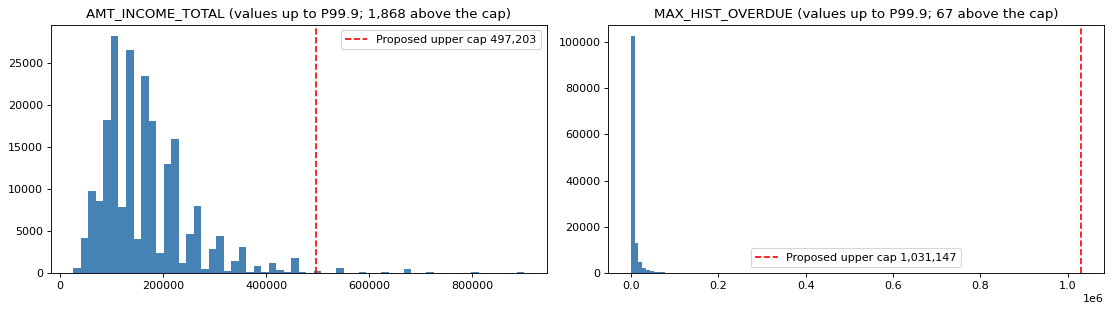

In [16]:
# illustrate the effect on two very skewed characteristics (temporary series only)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['AMT_INCOME_TOTAL', 'MAX_HIST_OVERDUE']):
    s = apply_invalid_preview(col).dropna()
    upper = capping_table.loc[col, 'Upper cap']
    ax.hist(s[s <= s.quantile(0.999)], bins=60, color='steelblue')
    ax.axvline(upper, color='red', linestyle='--', label=f'Proposed upper cap {upper:,.0f}')
    ax.set_title(f'{col} (values up to P99.9; {(s > upper).sum():,} above the cap)')
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretation**

- **Scope.** Ten characteristics are proposed for capping, affecting about 19,400 values in total (0.01%-2.3% per characteristic, indicative on the full sample).
- **Not capped.** Six are excluded because their range is bounded by definition, or (for `AGE_YEARS`) because no value lies beyond 3 standard deviations. `MOST_RECENT_CREDIT_AGE` is deliberately **not** capped: the rule would merge 5,849 genuine values between 5.8 and 8 years into one value.
- **Very skewed amounts weaken the rule.** For `MAX_HIST_OVERDUE`, a few huge values (up to about 116 million) inflate the standard deviation to about 341,000, so the cap sits at about 1.03 million and only 67 values are capped. The tail is still very long below the cap. For heavily skewed characteristics, the later quantile-based binning does more of the work than the cap does.
- **Effect on high-risk observations.** Capping keeps extreme applicants at the top of the range: someone with very large past arrears is still in the highest group. It only removes the distance between the extreme value and the cap. WOE groups are therefore little affected, and the main benefit is for any analysis that uses the raw values.
- **Phase B.** The train/test split is deferred to the next step (user instruction), so the caps are estimated on all applicants after the invalid rules. No `TARGET` information is used. The caps are saved to the parameters file and are not re-estimated later.

## 4.6 Correlation and Redundancy Screening

Week 9 Ex Q2 flags pairs with correlation > 0.8 or < -0.8 and drops one of each pair. The same threshold, |r| > 0.8, is applied here to all numeric predictors (continuous, discrete, date-relative). 0/1 flags are checked separately, and text categories are excluded because a numeric correlation of codes would be meaningless.

**How this differs from the lab.** The lab drops the member of each pair with the weaker correlation to `BAD`. That is a `TARGET`-based decision and must be made on training data only. Here, each pair is resolved by **business and data-quality reasoning** (formula relationship, interpretability, missingness), so no `TARGET` information is used. Any pair that business reasoning cannot resolve would be decided in Phase B on the training sample. As the table shows, none remains.

In [17]:
numeric_predictors = [c for c in predictors if pd.api.types.is_numeric_dtype(merged_orig[c]) and merged_orig[c].nunique() > 2]
binary_predictors = [c for c in predictors if pd.api.types.is_numeric_dtype(merged_orig[c]) and merged_orig[c].nunique() == 2]

cor = merged_orig[numeric_predictors].corr()
binary_cor = merged_orig[binary_predictors].corr()

def high_pairs(matrix, threshold=0.8):
    upper = matrix.where(np.triu(np.ones(matrix.shape, dtype=bool), k=1)).stack()
    pairs = upper[upper.abs() > threshold].reset_index()
    pairs.columns = ['Feature A', 'Feature B', 'Correlation']
    return pairs.reindex(pairs['Correlation'].abs().sort_values(ascending=False).index).reset_index(drop=True)

pairs = pd.concat([high_pairs(cor), high_pairs(binary_cor)], ignore_index=True)

def relationship(a, b):
    stem = lambda c: c.rsplit('_', 1)[0] if c.endswith(('_AVG', '_MODE', '_MEDI')) else None
    if stem(a) and stem(a) == stem(b): return 'Same building measure (AVG / MODE / MEDI)'
    if a in building_cols and b in building_cols: return 'Related building measures'
    if {a, b} in ({'DAYS_BIRTH', 'AGE_YEARS'}, {'DAYS_EMPLOYED', 'EMPLOYMENT_YEARS'}): return 'Unit conversion'
    if 'FLAG_DAYS_EMPLOYED_SPECIAL' in (a, b) and 'FLAG_EMP_PHONE' in (a, b): return 'Exact inverse flags'
    if 'SOCIAL_CIRCLE' in a and 'SOCIAL_CIRCLE' in b: return 'Overlapping time windows'
    if a.startswith(('REG_', 'LIVE_')) and b.startswith(('REG_', 'LIVE_')): return 'Overlapping address-mismatch definitions'
    if a.startswith('REGION_RATING') and b.startswith('REGION_RATING'): return 'Same rating with / without city'
    if {a, b} == {'AMT_CREDIT', 'AMT_GOODS_PRICE'}: return 'Financial: loan usually equals goods price'
    if {a, b} == {'CNT_CHILDREN', 'CNT_FAM_MEMBERS'}: return 'Household size includes children'
    return 'Mathematical: one is calculated from the other or both share an input'

def pair_action(a, b):
    ra, rb = relevance.loc[a, 'Recommendation'], relevance.loc[b, 'Recommendation']
    if ra == 'KEEP' and rb == 'KEEP': return 'BOTH RETAINED: resolve on training data'
    if ra == 'KEEP': return f'Retain {a}, remove {b}'
    if rb == 'KEEP': return f'Retain {b}, remove {a}'
    return 'Both removed (other reasons, see 4.2)'

pairs['Relationship'] = [relationship(a, b) for a, b in zip(pairs['Feature A'], pairs['Feature B'])]
pairs['Proposed action'] = [pair_action(a, b) for a, b in zip(pairs['Feature A'], pairs['Feature B'])]
pairs['Justification'] = [relevance.loc[b if relevance.loc[a, 'Recommendation'] == 'KEEP' else a, 'Business justification']
                          for a, b in zip(pairs['Feature A'], pairs['Feature B'])]
pairs['Missing % A'] = merged_orig[pairs['Feature A']].isnull().mean().values * 100
pairs['Missing % B'] = merged_orig[pairs['Feature B']].isnull().mean().values * 100

building_pair = pairs['Relationship'].str.contains('building')
print(f'Pairs with |r| > 0.8: {len(pairs)} ({building_pair.sum()} between building variables, all proposed for removal)')
print(pairs['Proposed action'].str.split(':').str[0].str.replace(r'Retain .*', 'Retain one, remove the other', regex=True).value_counts().to_string())
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(pairs.loc[~building_pair, ['Feature A', 'Feature B', 'Correlation', 'Relationship', 'Proposed action', 'Justification', 'Missing % A', 'Missing % B']])

Pairs with |r| > 0.8: 121 (104 between building variables, all proposed for removal)
Proposed action
Both removed (other reasons, see 4.2)    113
Retain one, remove the other                8


,Feature A,Feature B,Correlation,Relationship,Proposed action,Justification,Missing % A,Missing % B
0,DAYS_EMPLOYED,EMPLOYMENT_YEARS,-1.000,Unit conversion,"Retain EMPLOYMENT_YEARS, remove DAYS_EMPLOYED","Same information as EMPLOYMENT_YEARS (r = -1.00) plus the 365243 code, which FLAG_DAYS_EMPLOYED_SPECIAL keeps",0.000,19.797
1,DAYS_BIRTH,AGE_YEARS,-1.000,Unit conversion,"Both removed (other reasons, see 4.2)",Same information as AGE_YEARS (r = -1.00); age not used as a characteristic (user decision),0.000,0.000
2,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.999,Overlapping time windows,"Both removed (other reasons, see 4.2)",Defaults among the applicant's social circle: judges the applicant by other people's behaviour,0.347,0.347
21,AMT_CREDIT,AMT_GOODS_PRICE,0.987,Financial: loan usually equals goods price,"Retain AMT_CREDIT, remove AMT_GOODS_PRICE",r = 0.99 with AMT_CREDIT; the difference is kept by CREDIT_TO_GOODS_RATIO,0.000,0.105
46,DAYS_EMPLOYED,EMPLOYMENT_AGE_RATIO,-0.956,Mathematical: one is calculated from the other or both share an input,"Both removed (other reasons, see 4.2)","Same information as EMPLOYMENT_YEARS (r = -1.00) plus the 365243 code, which FLAG_DAYS_EMPLOYED_SPECIAL keeps",0.000,19.797
47,EMPLOYMENT_YEARS,EMPLOYMENT_AGE_RATIO,0.956,Mathematical: one is calculated from the other or both share an input,"Retain EMPLOYMENT_YEARS, remove EMPLOYMENT_AGE_RATIO","r = 0.96 with EMPLOYMENT_YEARS, which is easier to interpret",19.797,19.797
48,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,0.951,Same rating with / without city,"Both removed (other reasons, see 4.2)",User decision: the lender's region rating is not relevant to the applicant's repayment ability,0.000,0.000
49,BUREAU_DEBT_TO_INCOME,TOTAL_EXPOSURE_TO_INCOME,0.945,Mathematical: one is calculated from the other or both share an input,"Retain BUREAU_DEBT_TO_INCOME, remove TOTAL_EXPOSURE_TO_INCOME",r = 0.94 with BUREAU_DEBT_TO_INCOME; the new loan is already in LOAN_TO_INCOME,18.177,18.177
72,AMT_INCOME_TOTAL,INCOME_PER_FAMILY_MEMBER,0.888,Mathematical: one is calculated from the other or both share an input,"Retain AMT_INCOME_TOTAL, remove INCOME_PER_FAMILY_MEMBER",r = 0.89 with AMT_INCOME_TOTAL; also depends on family size (fairness proxy),0.000,0.001
76,CNT_CHILDREN,CNT_FAM_MEMBERS,0.880,Household size includes children,"Both removed (other reasons, see 4.2)",Proxy for family status,0.000,0.001


In [18]:
# building pairs summarised (all building variables are proposed for removal in 4.2)
pairs.loc[building_pair].groupby('Relationship').agg(Pairs=('Correlation', 'size'),
                                                      Min_abs_r=('Correlation', lambda s: s.abs().min()),
                                                      Max_abs_r=('Correlation', lambda s: s.abs().max()))

,Pairs,Min_abs_r,Max_abs_r
Relationship,,,
Related building measures,62,0.8061,0.9432
Same building measure (AVG / MODE / MEDI),42,0.9593,0.9985


In [19]:
# confirm that no pair of proposed candidates exceeds the threshold
candidate_cols = relevance.index[relevance['Recommendation'] == 'KEEP'].tolist()
candidate_numeric = [c for c in candidate_cols if c in numeric_predictors + binary_predictors]
candidate_pairs = high_pairs(merged_orig[candidate_numeric].corr())
print(f'Numeric candidates checked: {len(candidate_numeric)} | pairs with |r| > 0.8 among them: {len(candidate_pairs)}')

remaining = merged_orig[candidate_numeric].corr().where(np.triu(np.ones((len(candidate_numeric),) * 2, dtype=bool), k=1)).stack()
print('Highest remaining |r| among candidates:')
remaining.abs().sort_values(ascending=False).head(5).round(3).to_frame('|r|')

Numeric candidates checked: 24 | pairs with |r| > 0.8 among them: 0


Highest remaining |r| among candidates:


|r|
LOAN_TO_INCOME    ANNUITY_TO_INCOME        0.7920
ACTIVE_LOAN_COUNT ACTIVE_CREDIT_CARD_COUNT 0.7700
BUREAU_LOAN_COUNT ACTIVE_LOAN_COUNT        0.6910
AMT_CREDIT        CREDIT_TO_ANNUITY_RATIO  0.6670
                  LOAN_TO_INCOME           0.6600

**Interpretation**

- **121 pairs exceed |r| > 0.8.** 104 are between building variables: 42 AVG/MODE/MEDI duplicates (0.96-0.998) and 62 between related building measures (0.81-0.94). All of these columns are proposed for removal anyway.
- **The remaining 17 pairs are all explained by construction:**
  - unit conversions (days vs years)
  - an exact inverse flag (`FLAG_EMP_PHONE` vs the special-employment flag)
  - formula relationships (ratio vs its input)
  - overlapping definitions (30- vs 60-day windows, region rating with and without city, address-mismatch flags)
  - loan amount vs goods price
- **Resolution.** In 10 pairs one member is retained and the other removed, choosing the more interpretable or less missing measure. In the other 7, both members are removed for other reasons.
- **No `TARGET` was used** to resolve any pair, so the Week 9 weaker-correlation rule is not needed and no pair is left to resolve on training data.
- **Check on the proposed candidates.** No pair of candidates exceeds 0.8. The highest remaining correlations are `LOAN_TO_INCOME` / `ANNUITY_TO_INCOME` (0.79) and `ACTIVE_LOAN_COUNT` / `ACTIVE_CREDIT_CARD_COUNT` (0.77). Both are below the threshold and measure different concepts (loan size vs instalment burden; all credit vs revolving credit), so both are kept for IV screening.

## 4.7 Feature Engineering and Extraction Opportunities

Week 9 asked which variables would be more useful combined as a ratio or difference. Many such features already exist from Steps 1 and 2, so the first step is an inventory, to avoid recreating them.

In [20]:
existing_features = pd.DataFrame([
    ('LOAN_TO_INCOME', 'AMT_CREDIT / AMT_INCOME_TOTAL', 'Step 2'),
    ('ANNUITY_TO_INCOME', 'AMT_ANNUITY / AMT_INCOME_TOTAL', 'Step 2'),
    ('CREDIT_TO_GOODS_RATIO', 'AMT_CREDIT / AMT_GOODS_PRICE', 'Step 2'),
    ('CREDIT_TO_ANNUITY_RATIO', 'AMT_CREDIT / AMT_ANNUITY', 'Step 2'),
    ('INCOME_PER_FAMILY_MEMBER', 'AMT_INCOME_TOTAL / CNT_FAM_MEMBERS', 'Step 2'),
    ('EMPLOYMENT_YEARS', '-DAYS_EMPLOYED / 365.25 (missing for 365243)', 'Step 2'),
    ('EMPLOYMENT_AGE_RATIO', 'EMPLOYMENT_YEARS / AGE_YEARS', 'Step 2'),
    ('BUREAU_DEBT_TO_INCOME', 'TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL', 'Step 2'),
    ('TOTAL_EXPOSURE_TO_INCOME', '(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL', 'Step 2'),
    ('AVG_DEBT_PER_ACTIVE_LOAN', 'TOTAL_ACTIVE_DEBT / ACTIVE_LOAN_COUNT', 'Step 2'),
    ('EXISTING_DEBT_SHARE_OF_EXPOSURE', 'TOTAL_ACTIVE_DEBT / (TOTAL_ACTIVE_DEBT + AMT_CREDIT)', 'Step 2'),
    ('ACTIVE_LOAN_RATIO', 'ACTIVE_LOAN_COUNT / BUREAU_LOAN_COUNT', 'Step 1'),
    ('DEBT_TO_CREDIT_RATIO', 'TOTAL_ACTIVE_DEBT / TOTAL_ACTIVE_CREDIT', 'Step 1'),
], columns=['Existing characteristic', 'Formula', 'Created in'])
existing_features['Proposed status'] = [relevance.loc[c, 'Recommendation'] for c in existing_features['Existing characteristic']]
existing_features

,Existing characteristic,Formula,Created in,Proposed status
0,LOAN_TO_INCOME,AMT_CREDIT / AMT_INCOME_TOTAL,Step 2,KEEP
1,ANNUITY_TO_INCOME,AMT_ANNUITY / AMT_INCOME_TOTAL,Step 2,KEEP
2,CREDIT_TO_GOODS_RATIO,AMT_CREDIT / AMT_GOODS_PRICE,Step 2,KEEP
3,CREDIT_TO_ANNUITY_RATIO,AMT_CREDIT / AMT_ANNUITY,Step 2,KEEP
4,INCOME_PER_FAMILY_MEMBER,AMT_INCOME_TOTAL / CNT_FAM_MEMBERS,Step 2,DROP
5,EMPLOYMENT_YEARS,-DAYS_EMPLOYED / 365.25 (missing for 365243),Step 2,KEEP
6,EMPLOYMENT_AGE_RATIO,EMPLOYMENT_YEARS / AGE_YEARS,Step 2,DROP
7,BUREAU_DEBT_TO_INCOME,TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL,Step 2,KEEP
8,TOTAL_EXPOSURE_TO_INCOME,(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL,Step 2,DROP
9,AVG_DEBT_PER_ACTIVE_LOAN,TOTAL_ACTIVE_DEBT / ACTIVE_LOAN_COUNT,Step 2,DROP


**Additional features considered.** The only feature recommended is the 12-month enquiry total. The data dictionary states that the six `AMT_REQ_CREDIT_BUREAU_*` windows are **mutually exclusive** (for example, "one month before application, excluding one week before application"). Their sum is therefore the total number of bureau enquiries in the 12 months before application. That is a standard credit-seeking measure, and it replaces six sparse columns, two of them more than 99% zero.

In [21]:
# preview only: the proposed enquiry total on a temporary series (not added to any DataFrame)
qrt_preview = apply_invalid_preview('AMT_REQ_CREDIT_BUREAU_QRT')
enquiry_total_preview = merged_orig[[c for c in enquiry_cols if c != 'AMT_REQ_CREDIT_BUREAU_QRT']].sum(axis=1, min_count=6 - 1) + qrt_preview
enquiry_total_preview[merged_orig[enquiry_cols].isnull().any(axis=1)] = np.nan

print('Preview of TOTAL_BUREAU_ENQUIRIES_12M (not created):')
print(enquiry_total_preview.describe().round(2).to_string())
print(f"Share of zero: {(enquiry_total_preview == 0).mean() * 100:.1f}% | max |r| with retained candidates: "
      f"{max(abs(enquiry_total_preview.corr(merged_orig[c])) for c in candidate_numeric):.3f}")

Preview of TOTAL_BUREAU_ENQUIRIES_12M (not created):
count   183,599.0000
mean          2.5700
std           2.2500
min           0.0000
25%           1.0000
50%           2.0000
75%           4.0000
max          31.0000


Share of zero: 15.0% | max |r| with retained candidates: 0.090


In [22]:
proposed_features = pd.DataFrame([
    ('TOTAL_BUREAU_ENQUIRIES_12M', 'All six AMT_REQ_CREDIT_BUREAU_* windows', 'HOUR + DAY + WEEK + MON + QRT + YEAR (missing if any window is missing)',
     'Credit-seeking intensity in the last 12 months, a standard bureau risk indicator; windows are exclusive so the sum is meaningful',
     'Replaces the six window columns (all proposed for removal)', 'RECOMMEND: create'),
    ('OVERDUE_LOAN_RATIO', 'OVERDUE_LOAN_COUNT, BUREAU_LOAN_COUNT', 'OVERDUE_LOAN_COUNT / BUREAU_LOAN_COUNT',
     'Delinquency frequency relative to the number of accounts',
     'Built in Step 1 and dropped as redundant with OVERDUE_LOAN_COUNT', 'Not recommended'),
    ('BUREAU_ANNUITY_TO_INCOME', 'Bureau AMT_ANNUITY, AMT_INCOME_TOTAL', 'TOTAL_ACTIVE_ANNUITY / AMT_INCOME_TOTAL',
     'Existing repayment obligations relative to income',
     'Input dropped in Step 1 (59% missing)', 'Not possible'),
    ('CREDIT_CARD_UTILISATION', 'Card debt, card limit', 'Active card debt / TOTAL_REVOLVING_LIMIT',
     'Revolving utilisation',
     'Card-level debt is not in the flattened data; overall utilisation already in DEBT_TO_CREDIT_RATIO', 'Not possible'),
    ('RESIDUAL_INCOME_PER_MEMBER', 'AMT_INCOME_TOTAL, AMT_ANNUITY, CNT_FAM_MEMBERS', '(income - annuity) / family members',
     'Disposable income per household member',
     'Annuity / income period not confirmed (Step 2); depends on family size (fairness proxy); close to ANNUITY_TO_INCOME', 'Not recommended'),
    ('PROPERTY_SIZE_INDEX', 'Building _AVG fields', 'Average of normalised size measures',
     'Property-related consolidation',
     'Describes the building where the applicant lives, 46.7-69.4% missing', 'Not recommended'),
    ('ANY_DELINQUENCY_FLAG', 'OVERDUE_LOAN_COUNT, ADVERSE_STATUS_COUNT', '1 if either > 0',
     'Simple delinquency indicator',
     'WOE grouping of the two counts (0 vs >= 1) already gives this', 'Not recommended'),
], columns=['Proposed new characteristic', 'Source columns', 'Formula', 'Business justification', 'Potential redundancy', 'Recommendation'])
proposed_features

,Proposed new characteristic,Source columns,Formula,Business justification,Potential redundancy,Recommendation
0,TOTAL_BUREAU_ENQUIRIES_12M,All six AMT_REQ_CREDIT_BUREAU_* windows,HOUR + DAY + WEEK + MON + QRT + YEAR (missing if any window is missing),"Credit-seeking intensity in the last 12 months, a standard bureau risk indicator; windows are exclusive so the sum is meaningful",Replaces the six window columns (all proposed for removal),RECOMMEND: create
1,OVERDUE_LOAN_RATIO,"OVERDUE_LOAN_COUNT, BUREAU_LOAN_COUNT",OVERDUE_LOAN_COUNT / BUREAU_LOAN_COUNT,Delinquency frequency relative to the number of accounts,Built in Step 1 and dropped as redundant with OVERDUE_LOAN_COUNT,Not recommended
2,BUREAU_ANNUITY_TO_INCOME,"Bureau AMT_ANNUITY, AMT_INCOME_TOTAL",TOTAL_ACTIVE_ANNUITY / AMT_INCOME_TOTAL,Existing repayment obligations relative to income,Input dropped in Step 1 (59% missing),Not possible
3,CREDIT_CARD_UTILISATION,"Card debt, card limit",Active card debt / TOTAL_REVOLVING_LIMIT,Revolving utilisation,Card-level debt is not in the flattened data; overall utilisation already in DEBT_TO_CREDIT_RATIO,Not possible
4,RESIDUAL_INCOME_PER_MEMBER,"AMT_INCOME_TOTAL, AMT_ANNUITY, CNT_FAM_MEMBERS",(income - annuity) / family members,Disposable income per household member,Annuity / income period not confirmed (Step 2); depends on family size (fairness proxy); close to ANNUITY_TO_INCOME,Not recommended
5,PROPERTY_SIZE_INDEX,Building _AVG fields,Average of normalised size measures,Property-related consolidation,"Describes the building where the applicant lives, 46.7-69.4% missing",Not recommended
6,ANY_DELINQUENCY_FLAG,"OVERDUE_LOAN_COUNT, ADVERSE_STATUS_COUNT",1 if either > 0,Simple delinquency indicator,WOE grouping of the two counts (0 vs >= 1) already gives this,Not recommended


**Interpretation**

- **Recommended.** Only one new characteristic is recommended: `TOTAL_BUREAU_ENQUIRIES_12M`.
  - The dictionary defines the six enquiry windows as mutually exclusive, so their sum is a genuine 12-month count.
  - In the preview it has a median of 2, a maximum of 31 and only 15% zeros.
  - Its correlation with every retained candidate is at most 0.09, so it adds new information.
  - It replaces six columns, two of which are more than 99% zero.
- **Not recommended:**
  - Two features are not possible because their inputs were removed in Step 1 or never existed.
  - One recreates a feature Step 1 already dropped as redundant.
  - The others either duplicate what WOE grouping will do or depend on the building data or the family-size proxy.
- If the new feature is not approved, the fallback is to keep `AMT_REQ_CREDIT_BUREAU_MON` and `AMT_REQ_CREDIT_BUREAU_YEAR` as they are.

## 4.8 Proposed Characteristic Reduction

### Drop register

Every characteristic proposed for removal is listed individually, grouped by primary reason. The correlation evidence column shows the strongest correlation with any retained candidate (numeric characteristics only), which helps judge whether its information survives in the retained set.

In [23]:
candidate_set = set(candidate_cols)

def correlation_evidence(col):
    if col not in numeric_predictors + binary_predictors:
        return 'n/a (text)'
    others = [c for c in candidate_numeric if c != col]
    with np.errstate(divide='ignore', invalid='ignore'):
        r = merged_orig[others].corrwith(merged_orig[col])
    if r.abs().max() != r.abs().max():
        return 'n/a'
    best = r.abs().idxmax()
    return f'{r[best]:+.2f} with {best}'

drop_register = relevance[relevance['Recommendation'] == 'DROP'].copy()
drop_register['Correlation evidence'] = [correlation_evidence(c) for c in drop_register.index]
drop_register['Approval'] = 'Pending'
drop_register = drop_register.reset_index().rename(columns={'Column': 'Characteristic'})
drop_register = drop_register.sort_values(['Primary reason', 'Characteristic']).reset_index(drop=True)
drop_register.index = drop_register.index + 1

print(drop_register['Primary reason'].value_counts().to_string())
print(f'Total proposed removals: {len(drop_register)}')
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(drop_register[['Characteristic', 'Proposed decision', 'Primary reason', 'Missing %', 'Correlation evidence', 'Business justification', 'Approval']])

Primary reason
High missingness                     49
Near-zero variance                   23
High redundancy                      22
Business irrelevance                 17
Fairness, availability or leakage    14
Invalid or unusable                   2
Total proposed removals: 127


,Characteristic,Proposed decision,Primary reason,Missing %,Correlation evidence,Business justification,Approval
1,AGE_YEARS,DROP,Business irrelevance,0.00,+0.62 with FLAG_DAYS_EMPLOYED_SPECIAL,User decision: age eligibility (18+) is already enforced by the Step 0 segmentation; age is not used as a scoring characteristic,Pending
2,CREDIT_TYPE_DIVERSITY,DROP,Business irrelevance,14.75,+0.49 with BUREAU_LOAN_COUNT,"Indirect bureau descriptors (mix of credit types, time since last closure, bureau reporting timing); risk content covered by retained co...",Pending
3,DAYS_ID_PUBLISH,DROP,Business irrelevance,0.00,-0.29 with FLAG_DAYS_EMPLOYED_SPECIAL,"Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)",Pending
4,DAYS_LAST_PHONE_CHANGE,DROP,Business irrelevance,0.00,-0.17 with OLDEST_CREDIT_AGE,"Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)",Pending
5,DAYS_REGISTRATION,DROP,Business irrelevance,0.00,-0.21 with FLAG_DAYS_EMPLOYED_SPECIAL,"Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)",Pending
6,FLAG_DOCUMENT_3,DROP,Business irrelevance,0.00,-0.25 with FLAG_DAYS_EMPLOYED_SPECIAL,Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59),Pending
7,FLAG_DOCUMENT_6,DROP,Business irrelevance,0.00,+0.59 with FLAG_DAYS_EMPLOYED_SPECIAL,Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59),Pending
8,FLAG_DOCUMENT_8,DROP,Business irrelevance,0.00,-0.12 with FLAG_DAYS_EMPLOYED_SPECIAL,Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59),Pending
9,FLAG_EMAIL,DROP,Business irrelevance,0.00,-0.07 with FLAG_DAYS_EMPLOYED_SPECIAL,"Contactability, not repayment ability; administrative information",Pending
10,FLAG_PHONE,DROP,Business irrelevance,0.00,-0.09 with CREDIT_TO_GOODS_RATIO,"Contactability, not repayment ability; administrative information",Pending


### Retention list

In [24]:
def quality_concerns(col):
    notes = []
    pct = merged_orig[col].isnull().mean() * 100
    if pct > 0:
        notes.append(f'{pct:.1f}% missing')
    rule_ids = [r['id'] for r in invalid_rules if col in r['set_missing']]
    if rule_ids:
        notes.append(f"invalid rule {', '.join(rule_ids)}")
    if col in to_cap.index:
        notes.append(f"capping (~{int(to_cap.loc[col, 'Values below'] + to_cap.loc[col, 'Values above']):,} values)")
    if relevance.loc[col, 'Proposed decision'] == 'REVIEW':
        notes.append('REVIEW decision')
    return '; '.join(notes) or 'None'

retention = relevance.loc[candidate_cols, ['Business category', 'Primary reason', 'Business justification']].copy()
retention.columns = ['Business category', 'Risk dimension', 'Why retain?']

retention['Data-quality concerns'] = [quality_concerns(c) for c in retention.index]
retention['Later screening required?'] = 'Yes: WOE/IV on training data'
retention.loc['TOTAL_BUREAU_ENQUIRIES_12M (proposed new)'] = ['Credit history and recency', 'Credit history',
    'Credit-seeking intensity in the last 12 months (4.7)', f"{enquiry_total_preview.isnull().mean() * 100:.1f}% missing; requires approval",
    'Yes: WOE/IV on training data']
retention.index.name = 'Characteristic'
retention = retention.sort_values('Risk dimension')
retention.index = [f'{i + 1}. {c}' for i, c in enumerate(retention.index)]

print(retention['Risk dimension'].value_counts().to_string())
print(f'\nEstimated post-reduction candidate count: {len(retention)} '
      f"({len(candidate_cols)} existing characteristics + {len(retention) - len(candidate_cols)} proposed new feature)")
retention

Risk dimension
Credit exposure         10
Affordability            6
Employment stability     5
Delinquency              4
Credit history           3
Housing and assets       2
Loan characteristics     1

Estimated post-reduction candidate count: 31 (30 existing characteristics + 1 proposed new feature)


,Business category,Risk dimension,Why retain?,Data-quality concerns,Later screening required?
1. AMT_INCOME_TOTAL,Income and affordability,Affordability,Primary measure of repayment capacity; directly reported by the applicant,"invalid rule R4; capping (~1,868 values)",Yes: WOE/IV on training data
2. AMT_CREDIT,Loan characteristics,Affordability,Size of the exposure the lender takes on,"capping (~2,533 values)",Yes: WOE/IV on training data
3. CREDIT_TO_ANNUITY_RATIO,Loan characteristics,Affordability,"Implied number of instalments, i.e. loan term; longer terms carry more uncertainty",0.0% missing; capping (~14 values),Yes: WOE/IV on training data
4. CREDIT_TO_GOODS_RATIO,Loan characteristics,Affordability,"Borrowing above the goods price (fees, insurance, extra cash); EDA showed a different profile for bads","0.1% missing; capping (~1,788 values)",Yes: WOE/IV on training data
5. ANNUITY_TO_INCOME,Income and affordability,Affordability,"Instalment burden relative to income (same-period relative index, Step 2)","0.0% missing; invalid rule R4, R5; capping (~2,667 values)",Yes: WOE/IV on training data
6. LOAN_TO_INCOME,Income and affordability,Affordability,Loan size relative to income: standard leverage measure,"invalid rule R4; capping (~3,229 values)",Yes: WOE/IV on training data
7. ACTIVE_LOAN_COUNT,Historical credit exposure,Credit exposure,Number of current obligations; steady bad-rate gradient in EDA,14.8% missing,Yes: WOE/IV on training data
8. EXISTING_DEBT_SHARE_OF_EXPOSURE,Historical credit exposure,Credit exposure,How much of the total post-loan exposure is existing debt,18.2% missing,Yes: WOE/IV on training data
9. MORTGAGE_COUNT,Historical credit exposure,Credit exposure,"Existing housing debt, directly relevant for homeowners",14.8% missing,Yes: WOE/IV on training data
10. MICROLOAN_COUNT,Historical credit exposure,Credit exposure,Short-term high-cost credit; one microloan had an 18.6% bad rate (EDA),14.8% missing,Yes: WOE/IV on training data


**Interpretation**

- **Reduction.** The candidate set falls from **157 to 31**: 30 existing characteristics plus 1 proposed new feature. That is within the 20-35 target.
- **Every retained characteristic carries a distinct, explainable risk concept:**
  - existing credit exposure (10)
  - affordability (6)
  - employment stability (5)
  - delinquency (4)
  - credit history (3, including the proposed enquiry total)
  - housing and assets (2)
  - loan type (1)
- **No pair of retained characteristics exceeds the 0.8 correlation threshold**, so cutting further now would mean dropping real information before its predictive strength is known. That is the job of IV screening on the training data, which is expected to remove the weakest of these 31 (for example the near-zero-variance `TOTAL_PROLONGATIONS` or `MORTGAGE_COUNT`).
- If the new enquiry feature is not approved, `AMT_REQ_CREDIT_BUREAU_MON` and `AMT_REQ_CREDIT_BUREAU_YEAR` replace it, giving 32.

## 4.9 Final Approval Report

A concise summary of every decision that needs approval. Nothing in this report has been applied to the data.

### A. Proposed removals (by primary reason)

In [25]:
removals = (drop_register.groupby('Primary reason')['Characteristic']
            .agg(Count='size', Characteristics=lambda s: ', '.join(s)))
removals.loc['Total'] = [removals['Count'].sum(), '']
removals

,Count,Characteristics
Primary reason,,
Business irrelevance,17,"AGE_YEARS, CREDIT_TYPE_DIVERSITY, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE, DAYS_REGISTRATION, FLAG_DOCUMENT_3, FLAG_DOCUMENT_6, FLAG_DOC..."
"Fairness, availability or leakage",14,"CNT_CHILDREN, CODE_GENDER, DEF_30_CNT_SOCIAL_CIRCLE, DEF_60_CNT_SOCIAL_CIRCLE, LIVE_CITY_NOT_WORK_CITY, LIVE_REGION_NOT_WORK_REGION, NAM..."
High missingness,49,"APARTMENTS_AVG, APARTMENTS_MEDI, APARTMENTS_MODE, BASEMENTAREA_AVG, BASEMENTAREA_MEDI, BASEMENTAREA_MODE, COMMONAREA_AVG, COMMONAREA_MED..."
High redundancy,22,"ACTIVE_CONSUMER_CREDIT_COUNT, ACTIVE_LOANS_PER_INCOME, AMT_ANNUITY, AMT_GOODS_PRICE, AMT_REQ_CREDIT_BUREAU_MON, AMT_REQ_CREDIT_BUREAU_QR..."
Invalid or unusable,2,"MAX_REMAINING_DURATION, ORGANIZATION_TYPE"
Near-zero variance,23,"AMT_REQ_CREDIT_BUREAU_DAY, AMT_REQ_CREDIT_BUREAU_HOUR, FLAG_CONT_MOBILE, FLAG_DOCUMENT_10, FLAG_DOCUMENT_11, FLAG_DOCUMENT_12, FLAG_DOCU..."
Total,127,


### B. More than 40% missing

In [26]:
over40[['Missing %', 'Recommendation']].assign(Decision='Pending').style.format({'Missing %': '{:.1f}'})

,Missing %,Recommendation,Decision
Characteristic,,,
COMMONAREA_AVG,69.4,DROP,Pending
COMMONAREA_MODE,69.4,DROP,Pending
COMMONAREA_MEDI,69.4,DROP,Pending
NONLIVINGAPARTMENTS_AVG,69.0,DROP,Pending
NONLIVINGAPARTMENTS_MODE,69.0,DROP,Pending
NONLIVINGAPARTMENTS_MEDI,69.0,DROP,Pending
FONDKAPREMONT_MODE,67.9,DROP,Pending
LIVINGAPARTMENTS_AVG,67.9,DROP,Pending
LIVINGAPARTMENTS_MEDI,67.9,DROP,Pending


### C. Invalid-value rules

In [27]:
invalid_table[['Characteristic', 'Invalid-value rule', 'Invalid count', 'Proposed treatment', 'Ambiguous (needs approval)']]

,Characteristic,Invalid-value rule,Invalid count,Proposed treatment,Ambiguous (needs approval)
Rule,,,,,
R1,DAYS_EMPLOYED,DAYS_EMPLOYED == 365243,42230,Set to NaN: DAYS_EMPLOYED,No
R2,CODE_GENDER,CODE_GENDER == 'XNA',4,Set to NaN: CODE_GENDER,No
R3,ORGANIZATION_TYPE,ORGANIZATION_TYPE == 'XNA',42230,Set to NaN: ORGANIZATION_TYPE,No
R4,AMT_INCOME_TOTAL (+ income-based ratios),"AMT_INCOME_TOTAL > 20,000,000",1,"Set to NaN: AMT_INCOME_TOTAL, LOAN_TO_INCOME, ANNUITY_TO_INCOME, INCOME_PER_FAMILY_MEMBER, BUREAU_DEBT_TO_INCOME, TOTAL_EXPOSURE_TO_INCO...",Yes
R5,ANNUITY_TO_INCOME,ANNUITY_TO_INCOME > 1,23,Set to NaN: ANNUITY_TO_INCOME,Yes
R6,DEBT_TO_CREDIT_RATIO,DEBT_TO_CREDIT_RATIO > 10,4,Set to NaN: DEBT_TO_CREDIT_RATIO,Yes
R7,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_QRT > 30,1,Set to NaN: AMT_REQ_CREDIT_BUREAU_QRT,Yes
R8,OWN_CAR_AGE,OWN_CAR_AGE > 50,2482,Set to NaN: OWN_CAR_AGE,Yes


### D. Valid-outlier capping (Z-score, +/-3 std)

In [28]:
to_cap[['Lower cap', 'Upper cap', 'Values below', 'Values above', '% affected']].style.format('{:,.3f}', subset=['Lower cap', 'Upper cap', '% affected'])

,Lower cap,Upper cap,Values below,Values above,% affected
Characteristic,,,,,
AMT_INCOME_TOTAL,"-159,777.364","497,202.512",0,1868,0.876
AMT_CREDIT,"-596,639.800","1,773,684.844",0,2533,1.187
LOAN_TO_INCOME,-4.054,11.795,0,3229,1.514
ANNUITY_TO_INCOME,-0.100,0.459,0,2667,1.250
CREDIT_TO_ANNUITY_RATIO,-1.490,43.940,0,14,0.007
CREDIT_TO_GOODS_RATIO,0.752,1.499,160,1628,0.839
EMPLOYMENT_YEARS,-12.967,26.292,0,3877,2.266
BUREAU_DEBT_TO_INCOME,-18.922,26.301,0,3145,1.802
DEBT_TO_CREDIT_RATIO,-0.451,1.561,0,255,0.182


### E. Feature engineering

| New characteristic | Formula | Justification |
|---|---|---|
| `TOTAL_BUREAU_ENQUIRIES_12M` | Sum of the six exclusive `AMT_REQ_CREDIT_BUREAU_*` windows; missing if any window is missing | 12-month credit-seeking intensity; replaces six sparse columns |

No other new characteristic is recommended (4.7).

### F. Proposed final candidates and summary

In [29]:
print('Proposed final candidates:')
print(', '.join(c.split('. ', 1)[1] for c in retention.index))

reason_counts = drop_register['Primary reason'].value_counts()
business_drops = reason_counts.get('Business irrelevance', 0) + reason_counts.get('Fairness, availability or leakage', 0)
summary_table = pd.DataFrame({'Result': [
    len(predictors),
    business_drops,
    reason_counts.get('High missingness', 0),
    reason_counts.get('High redundancy', 0),
    reason_counts.get('Invalid or unusable', 0) + reason_counts.get('Near-zero variance', 0),
    1,
    len(predictors) - len(drop_register) + 1,
]}, index=['Initial predictor characteristics',
           'Proposed business-knowledge drops (incl. fairness)',
           'Proposed missingness drops',
           'Proposed redundancy drops',
           'Proposed other drops (invalid / unusable, near-zero variance)',
           'Additional features proposed',
           'Expected final candidate characteristics'])
assert summary_table.iloc[1:5, 0].sum() == len(drop_register), 'removal counts do not add up'
summary_table

Proposed final candidates:
AMT_INCOME_TOTAL, AMT_CREDIT, CREDIT_TO_ANNUITY_RATIO, CREDIT_TO_GOODS_RATIO, ANNUITY_TO_INCOME, LOAN_TO_INCOME, ACTIVE_LOAN_COUNT, EXISTING_DEBT_SHARE_OF_EXPOSURE, MORTGAGE_COUNT, MICROLOAN_COUNT, DEBT_TO_CREDIT_RATIO, ACTIVE_CREDIT_CARD_COUNT, HAS_BUREAU_HISTORY, BUREAU_LOAN_COUNT, BUREAU_DEBT_TO_INCOME, ACTIVE_LOAN_RATIO, MOST_RECENT_CREDIT_AGE, OLDEST_CREDIT_AGE, TOTAL_BUREAU_ENQUIRIES_12M (proposed new), TOTAL_PROLONGATIONS, OVERDUE_LOAN_COUNT, ADVERSE_STATUS_COUNT, MAX_HIST_OVERDUE, FLAG_DAYS_EMPLOYED_SPECIAL, EMPLOYMENT_YEARS, OCCUPATION_TYPE, NAME_EDUCATION_TYPE, NAME_INCOME_TYPE, NAME_HOUSING_TYPE, FLAG_OWN_CAR, NAME_CONTRACT_TYPE


,Result
Initial predictor characteristics,157
Proposed business-knowledge drops (incl. fairness),31
Proposed missingness drops,49
Proposed redundancy drops,22
"Proposed other drops (invalid / unusable, near-zero variance)",25
Additional features proposed,1
Expected final candidate characteristics,31


### Approval checklist

**Phase A ends here.** The items below were put to the user and **approved on 2026-10-30** (with the amendments listed in the configuration section):

1. **Drop list (A):** all characteristics proposed for removal, including the REVIEW items recommended for DROP (`ORGANIZATION_TYPE`, `AMT_REQ_CREDIT_BUREAU_MON`, `AMT_REQ_CREDIT_BUREAU_YEAR`).
2. **More than 40% missing (B):** drop the 47 building variables, `OWN_CAR_AGE` and `EXT_SOURCE_1` (user decision); keep `MAX_HIST_OVERDUE` with a missing bin (user decision).
3. **Invalid-value rules (C):** R1-R3 (codes), plus the ambiguous rules R4-R8.
4. **Outlier capping (D):** Z-score capping at +/-3 std for the listed characteristics.
5. **Missing-value treatments (4.3), as instructed:** genuine missing values stay missing (WOE missing bin); only values removed by an invalid-value rule get the median of the valid values.
6. **Additional engineered feature (E):** `TOTAL_BUREAU_ENQUIRIES_12M`.
7. **Final candidate list (F).** Already decided: `AGE_YEARS`, `EXT_SOURCE_1` and `REGION_RATING_CLIENT` removed; `MAX_HIST_OVERDUE` kept.

## Configuration: approved decisions

The Phase A proposals were **approved by the user on 2026-10-30**, with these amendments made during review:

- `EXT_SOURCE_1`, `AGE_YEARS` and `REGION_RATING_CLIENT` removed; `MAX_HIST_OVERDUE` kept.
- Genuine missing values are kept as missing; only values set to missing by an invalid-value rule are replaced with a median.
- **No train/test split in this step** (user instruction). The split is made in the next step (grouping and WOE/IV screening).

Phase B reads **only** this configuration. The retained columns are written out explicitly so the preparation can be reproduced, and they are checked against the Phase A proposals.

In [30]:
APPROVED = True
APPROVAL_DATE = '2026-10-30'

APPROVED_CONFIG = {
    'keep_columns': [
        # affordability and loan
        'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_ANNUITY_RATIO',
        'CREDIT_TO_GOODS_RATIO', 'NAME_CONTRACT_TYPE',
        # employment and stability
        'EMPLOYMENT_YEARS', 'FLAG_DAYS_EMPLOYED_SPECIAL', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE',
        # housing and assets
        'NAME_HOUSING_TYPE', 'FLAG_OWN_CAR',
        # existing credit exposure
        'HAS_BUREAU_HISTORY', 'BUREAU_LOAN_COUNT', 'ACTIVE_LOAN_COUNT', 'ACTIVE_LOAN_RATIO', 'ACTIVE_CREDIT_CARD_COUNT',
        'BUREAU_DEBT_TO_INCOME', 'DEBT_TO_CREDIT_RATIO', 'EXISTING_DEBT_SHARE_OF_EXPOSURE', 'MORTGAGE_COUNT', 'MICROLOAN_COUNT',
        # delinquency
        'ADVERSE_STATUS_COUNT', 'OVERDUE_LOAN_COUNT', 'TOTAL_PROLONGATIONS', 'MAX_HIST_OVERDUE',
        # credit history
        'OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE',
    ],
    'invalid_rules': ['R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8'],
    'invalid_value_treatment': 'median of the valid values',
    'genuine_missing_treatment': 'kept as missing (no imputation)',
    'cap_columns': ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_ANNUITY_RATIO',
                    'CREDIT_TO_GOODS_RATIO', 'EMPLOYMENT_YEARS', 'BUREAU_DEBT_TO_INCOME', 'DEBT_TO_CREDIT_RATIO', 'MAX_HIST_OVERDUE'],
    'cap_z': 3,
    'new_features': {'TOTAL_BUREAU_ENQUIRIES_12M': enquiry_cols},
    'train_test_split': 'not performed in this step (user instruction)',
}

# the approved configuration must match the Phase A proposals exactly
approved_drop = [c for c in predictors if c not in APPROVED_CONFIG['keep_columns']]
assert set(APPROVED_CONFIG['keep_columns']) == set(candidate_cols), 'keep list differs from Phase A'
assert set(approved_drop) == set(drop_register['Characteristic']), 'drop list differs from Phase A'
assert APPROVED_CONFIG['cap_columns'] == to_cap.index.tolist(), 'capping list differs from Phase A'
print(f"Approved on {APPROVAL_DATE}: keep {len(APPROVED_CONFIG['keep_columns'])} characteristics, "
      f"drop {len(approved_drop)}, {len(APPROVED_CONFIG['invalid_rules'])} invalid rules, "
      f"cap {len(APPROVED_CONFIG['cap_columns'])}, create {len(APPROVED_CONFIG['new_features'])} new feature")

Approved on 2026-10-30: keep 30 characteristics, drop 127, 8 invalid rules, cap 10, create 1 new feature


## 4.10 Implement Approved Data Preparation

The implementation follows the approved sequence:

1. Build a working copy (`prepared`). `merged_orig` is never modified.
2. Apply the invalid-value rules: the value becomes `NaN` and its position is recorded. No rows are removed.
3. Estimate the capping parameters (mean and standard deviation, after the invalid values have been removed).
4. Replace **only** the recorded invalid values with the median of the valid values.
5. Create `TOTAL_BUREAU_ENQUIRIES_12M`.
6. Apply the Z-score caps.
7. Keep only the approved columns.
8. Validate and export.

**About the split.** As instructed, no train/test split is made here. The medians and caps are therefore estimated on all 213,312 applicants. Neither uses `TARGET`: they are unsupervised, fixed, and saved to a parameters file, so they will not be re-estimated later. All `TARGET`-based work (binning, WOE/IV, characteristic selection) must still be done on the training sample created in the next step.

### Phase B, part 1 - Working copy

In [31]:
if not APPROVED:
    raise RuntimeError('Phase B requires APPROVED = True in the configuration')

work_cols = [id_col, target_col] + APPROVED_CONFIG['keep_columns'] + list(APPROVED_CONFIG['new_features']['TOTAL_BUREAU_ENQUIRIES_12M'])
prepared = merged_orig[work_cols].copy()
print(f'Working copy: {prepared.shape[0]:,} rows x {prepared.shape[1]} columns '
      f'(ID, TARGET, {len(APPROVED_CONFIG["keep_columns"])} retained characteristics, 6 enquiry inputs for the new feature)')

Working copy: 213,312 rows x 38 columns (ID, TARGET, 30 retained characteristics, 6 enquiry inputs for the new feature)


### Phase B, part 2 - Invalid values to `NaN`

Rules are evaluated on the original values. Rules on dropped columns (R1-R3, R8) have no effect on the prepared data and are reported as such.

In [32]:
rules_by_id = {r['id']: r for r in invalid_rules}
invalid_masks = {}
invalid_log = []

for rule_id in APPROVED_CONFIG['invalid_rules']:
    r = rules_by_id[rule_id]
    flagged = r['condition'](merged_orig).fillna(False).to_numpy()
    applied = [c for c in r['set_missing'] if c in prepared.columns]
    values_set = 0
    for col in applied:
        mask = flagged & prepared[col].notnull().to_numpy()
        prepared.loc[mask, col] = np.nan
        invalid_masks[col] = invalid_masks.get(col, np.zeros(len(prepared), dtype=bool)) | mask
        values_set += mask.sum()
    invalid_log.append({'Rule': rule_id, 'Rule text': r['rule'], 'Applicants flagged': int(flagged.sum()),
                        'Columns updated': ', '.join(applied) if applied else 'none (column dropped)',
                        'Values set to NaN': int(values_set)})

invalid_log = pd.DataFrame(invalid_log).set_index('Rule')
invalid_log

,Rule text,Applicants flagged,Columns updated,Values set to NaN
Rule,,,,
R1,DAYS_EMPLOYED == 365243,42230,none (column dropped),0
R2,CODE_GENDER == 'XNA',4,none (column dropped),0
R3,ORGANIZATION_TYPE == 'XNA',42230,none (column dropped),0
R4,"AMT_INCOME_TOTAL > 20,000,000",1,"AMT_INCOME_TOTAL, LOAN_TO_INCOME, ANNUITY_TO_INCOME, BUREAU_DEBT_TO_INCOME",4
R5,ANNUITY_TO_INCOME > 1,23,ANNUITY_TO_INCOME,23
R6,DEBT_TO_CREDIT_RATIO > 10,4,DEBT_TO_CREDIT_RATIO,4
R7,AMT_REQ_CREDIT_BUREAU_QRT > 30,1,AMT_REQ_CREDIT_BUREAU_QRT,1
R8,OWN_CAR_AGE > 50,2482,none (column dropped),0


### Phase B, part 3 - Capping parameters

Mean and standard deviation are estimated after the invalid values have been removed, as in the Phase A preview.

In [33]:
z = APPROVED_CONFIG['cap_z']
cap_params = {}
for col in APPROVED_CONFIG['cap_columns']:
    mean, std = prepared[col].mean(), prepared[col].std()
    cap_params[col] = {'mean': mean, 'std': std, 'lower': mean - z * std, 'upper': mean + z * std}
cap_params_table = pd.DataFrame(cap_params).T
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(cap_params_table)

,mean,std,lower,upper
AMT_INCOME_TOTAL,"168,712.5738","109,496.6460","-159,777.3642","497,202.5118"
AMT_CREDIT,"588,522.5220","395,054.1072","-596,639.7997","1,773,684.8437"
LOAN_TO_INCOME,3.8703,2.6414,-4.0540,11.7946
ANNUITY_TO_INCOME,0.1796,0.0933,-0.1003,0.4594
CREDIT_TO_ANNUITY_RATIO,21.2251,7.5718,-1.4901,43.9404
CREDIT_TO_GOODS_RATIO,1.1255,0.1245,0.7519,1.4991
EMPLOYMENT_YEARS,6.6626,6.5433,-12.9671,26.2924
BUREAU_DEBT_TO_INCOME,3.6894,7.5371,-18.9220,26.3008
DEBT_TO_CREDIT_RATIO,0.5553,0.3354,-0.4510,1.5615
MAX_HIST_OVERDUE,"8,711.9164","340,811.6719","-1,013,723.0993","1,031,146.9321"


### Phase B, part 4 - Median for the invalid values only

Each recorded invalid value is replaced with the median of that characteristic's valid values. Genuine missing values in the same columns are left missing.

In [34]:
median_values = {}
median_log = []
for col, mask in invalid_masks.items():
    median_values[col] = prepared[col].median()
    prepared.loc[mask, col] = median_values[col]
    median_log.append({'Characteristic': col, 'Invalid values replaced': int(mask.sum()), 'Median used': median_values[col],
                       'Genuine missing kept': int(prepared[col].isnull().sum()),
                       'Genuine missing in source': int(merged_orig[col].isnull().sum())})
median_log = pd.DataFrame(median_log).set_index('Characteristic')
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(median_log)

,Invalid values replaced,Median used,Genuine missing kept,Genuine missing in source
Characteristic,,,,
AMT_INCOME_TOTAL,1,"148,500.0000",0,0
LOAN_TO_INCOME,1,3.1600,0,0
ANNUITY_TO_INCOME,24,0.1618,3,3
BUREAU_DEBT_TO_INCOME,1,1.2618,38773,38773
DEBT_TO_CREDIT_RATIO,4,0.6096,73159,73159
AMT_REQ_CREDIT_BUREAU_QRT,1,0.0000,29712,29712


### Phase B, part 5 - New feature: `TOTAL_BUREAU_ENQUIRIES_12M`

The six enquiry windows are mutually exclusive (data dictionary), so their sum is the number of bureau enquiries in the 12 months before application. The result is missing when the windows are missing (they are always missing together, for applicants without bureau history). The six input columns are then removed, as approved.

In [35]:
inputs = APPROVED_CONFIG['new_features']['TOTAL_BUREAU_ENQUIRIES_12M']
prepared['TOTAL_BUREAU_ENQUIRIES_12M'] = prepared[inputs].sum(axis=1, min_count=len(inputs))
prepared = prepared.drop(columns=inputs)

print(prepared['TOTAL_BUREAU_ENQUIRIES_12M'].describe().round(2).to_string())
print(f"Missing: {prepared['TOTAL_BUREAU_ENQUIRIES_12M'].isnull().sum():,}")

count   183,600.0000
mean          2.5700
std           2.2500
min           0.0000
25%           1.0000
50%           2.0000
75%           4.0000
max          31.0000
Missing: 29,712


### Phase B, part 6 - Z-score capping

Values beyond mean +/- 3 standard deviations are set to the boundary. Missing values stay missing.

In [36]:
cap_log = []
for col, p in cap_params.items():
    below = int((prepared[col] < p['lower']).sum())
    above = int((prepared[col] > p['upper']).sum())
    prepared[col] = prepared[col].clip(lower=p['lower'], upper=p['upper'])
    cap_log.append({'Characteristic': col, 'Lower cap': p['lower'], 'Upper cap': p['upper'],
                    'Values raised to lower cap': below, 'Values lowered to upper cap': above,
                    '% of non-missing affected': (below + above) / prepared[col].notnull().sum() * 100})
cap_log = pd.DataFrame(cap_log).set_index('Characteristic')
print(f"Values capped: {int(cap_log[['Values raised to lower cap', 'Values lowered to upper cap']].sum().sum()):,}")
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(cap_log)

Values capped: 19,443


,Lower cap,Upper cap,Values raised to lower cap,Values lowered to upper cap,% of non-missing affected
Characteristic,,,,,
AMT_INCOME_TOTAL,"-159,777.3642","497,202.5118",0,1868,0.8757
AMT_CREDIT,"-596,639.7997","1,773,684.8437",0,2533,1.1875
LOAN_TO_INCOME,-4.0540,11.7946,0,3229,1.5137
ANNUITY_TO_INCOME,-0.1003,0.4594,0,2667,1.2503
CREDIT_TO_ANNUITY_RATIO,-1.4901,43.9404,0,14,0.0066
CREDIT_TO_GOODS_RATIO,0.7519,1.4991,160,1628,0.8391
EMPLOYMENT_YEARS,-12.9671,26.2924,0,3877,2.2662
BUREAU_DEBT_TO_INCOME,-18.9220,26.3008,0,3145,1.8019
DEBT_TO_CREDIT_RATIO,-0.4510,1.5615,0,255,0.1819


### Phase B, part 7 - Final columns and integrity checks

In [37]:
final_predictors = APPROVED_CONFIG['keep_columns'] + list(APPROVED_CONFIG['new_features'])
prepared = prepared[[id_col, target_col] + final_predictors]

numeric_final = [c for c in final_predictors if pd.api.types.is_numeric_dtype(prepared[c])]
final_cor = prepared[numeric_final].corr()
final_high_pairs = high_pairs(final_cor)

remaining_invalid = sum(int(r['condition'](prepared).fillna(False).sum())
                        for r in invalid_rules if all(c in prepared.columns for c in r['set_missing'][:1]))

checks = {
    'Same number of applicants (no rows removed)': len(prepared) == len(merged_orig),
    'Same applicants in the same order': prepared[id_col].equals(merged_orig[id_col]),
    'SK_ID_CURR unique': prepared[id_col].is_unique,
    'TARGET unchanged': prepared[target_col].equals(merged_orig[target_col]),
    f'{len(final_predictors)} predictors + ID + TARGET': prepared.shape[1] == len(final_predictors) + 2,
    'No invalid values remain (approved rules re-checked)': remaining_invalid == 0,
    'Genuine missing values unchanged (retained columns)': all(prepared[c].isnull().sum() == merged_orig[c].isnull().sum()
                                                                for c in APPROVED_CONFIG['keep_columns']),
    'All capped values within caps': all(prepared[c].dropna().between(p['lower'], p['upper']).all() for c, p in cap_params.items()),
    'No infinite values': not np.isinf(prepared[numeric_final]).any().any(),
    'No predictor pair with |r| > 0.8': len(final_high_pairs) == 0,
    'Source data unchanged (fingerprint)': pd.util.hash_pandas_object(merged_orig, index=True).sum() == original_fingerprint,
}
integrity = pd.DataFrame({'Passed': checks})
display(integrity)
if not integrity['Passed'].all():
    raise AssertionError('Integrity check failed: ' + ', '.join(integrity.index[~integrity['Passed']]))
print(f'Prepared data: {prepared.shape[0]:,} rows x {prepared.shape[1]} columns')

,Passed
Same number of applicants (no rows removed),True
Same applicants in the same order,True
SK_ID_CURR unique,True
TARGET unchanged,True
31 predictors + ID + TARGET,True
No invalid values remain (approved rules re-checked),True
Genuine missing values unchanged (retained columns),True
All capped values within caps,True
No infinite values,True
No predictor pair with |r| > 0.8,True


Prepared data: 213,312 rows x 33 columns


### Phase B, part 8 - Export

Two outputs are saved in `data/`:

- `prepared_data.csv`: one row per applicant with `SK_ID_CURR`, `TARGET` and the 31 prepared characteristics
- `prepared_data_parameters.json`: the approved decisions and every fitted value (medians, caps, rules), so later steps can apply exactly the same preparation without re-estimating anything

In [38]:
import json

output_path = 'data/prepared_data.csv'
params_path = 'data/prepared_data_parameters.json'
prepared.to_csv(output_path, index=False)

parameters = {
    'approval_date': APPROVAL_DATE,
    'source_file': merged_path,
    'rows': int(len(prepared)),
    'predictors': final_predictors,
    'dropped_columns': {reason: group['Characteristic'].tolist() for reason, group in drop_register.groupby('Primary reason')},
    'invalid_rules': {r: rules_by_id[r]['rule'] + ' -> NaN in ' + ', '.join(rules_by_id[r]['set_missing']) for r in APPROVED_CONFIG['invalid_rules']},
    'invalid_value_medians': {c: float(v) for c, v in median_values.items()},
    'z_caps': {c: {k: float(v) for k, v in p.items()} for c, p in cap_params.items()},
    'new_features': {'TOTAL_BUREAU_ENQUIRIES_12M': ' + '.join(inputs) + ' (missing if any window is missing)'},
    'genuine_missing_treatment': APPROVED_CONFIG['genuine_missing_treatment'],
    'fitted_on': 'all applicants (no train/test split in this step, user instruction); no TARGET information used',
}
with open(params_path, 'w') as f:
    json.dump(parameters, f, indent=2)

# confirm the export by reloading
reloaded = pd.read_csv(output_path)
print(f'Saved {output_path}: {reloaded.shape[0]:,} rows x {reloaded.shape[1]} columns, '
      f'{os.path.getsize(output_path) / 1e6:.1f} MB')
print(f'Saved {params_path}')
print('Reloaded file matches:', reloaded.shape == prepared.shape and reloaded[id_col].equals(prepared[id_col]))
del reloaded

Saved data/prepared_data.csv: 213,312 rows x 33 columns, 60.6 MB
Saved data/prepared_data_parameters.json
Reloaded file matches: True


## 4.11 Final Data Preparation Summary

In [39]:
predictors_before = merged_orig[predictors]
# invalid values in the source: every (rule, column) combination, retained or dropped
invalid_before = sum(int((rules_by_id[r]['condition'](merged_orig).fillna(False) & merged_orig[c].notnull()).sum())
                     for r in APPROVED_CONFIG['invalid_rules'] for c in rules_by_id[r]['set_missing'])
capped_total = int(cap_log[['Values raised to lower cap', 'Values lowered to upper cap']].sum().sum())

before_after = pd.DataFrame({
    'Before preparation': [f'{len(merged_orig):,}', len(predictors), f'{predictors_before.isnull().sum().sum():,}',
                           f'{invalid_before:,}', 0, len(pairs)],
    'After preparation': [f'{len(prepared):,}', len(final_predictors), f'{prepared[final_predictors].isnull().sum().sum():,}',
                          remaining_invalid, f'{capped_total:,}', len(final_high_pairs)],
}, index=['Rows', 'Predictor columns', 'Missing values (predictor cells)', 'Invalid observations',
          'Capped observations', 'High-correlation feature pairs (|r| > 0.8)'])
before_after

,Before preparation,After preparation
Rows,"213,312","213,312"
Predictor columns,157,31
Missing values (predictor cells),"7,491,844","725,426"
Invalid observations,"86,981",0
Capped observations,0,"19,443"
High-correlation feature pairs (|r| > 0.8),121,0


In [40]:
# characteristics dropped, by reason
display(removals)

# high-correlation characteristics removed (one member of each retained pair)
display(pairs.loc[pairs['Proposed action'].str.startswith('Retain'), ['Feature A', 'Feature B', 'Correlation', 'Proposed action']]
        .reset_index(drop=True))

# missing values in the prepared data (kept as missing for the WOE missing bin)
prepared_missing = prepared[final_predictors].isnull().mean().mul(100).round(2)
prepared_missing[prepared_missing > 0].sort_values(ascending=False).to_frame('Missing % (kept as missing)')

,Count,Characteristics
Primary reason,,
Business irrelevance,17,"AGE_YEARS, CREDIT_TYPE_DIVERSITY, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE, DAYS_REGISTRATION, FLAG_DOCUMENT_3, FLAG_DOCUMENT_6, FLAG_DOC..."
"Fairness, availability or leakage",14,"CNT_CHILDREN, CODE_GENDER, DEF_30_CNT_SOCIAL_CIRCLE, DEF_60_CNT_SOCIAL_CIRCLE, LIVE_CITY_NOT_WORK_CITY, LIVE_REGION_NOT_WORK_REGION, NAM..."
High missingness,49,"APARTMENTS_AVG, APARTMENTS_MEDI, APARTMENTS_MODE, BASEMENTAREA_AVG, BASEMENTAREA_MEDI, BASEMENTAREA_MODE, COMMONAREA_AVG, COMMONAREA_MED..."
High redundancy,22,"ACTIVE_CONSUMER_CREDIT_COUNT, ACTIVE_LOANS_PER_INCOME, AMT_ANNUITY, AMT_GOODS_PRICE, AMT_REQ_CREDIT_BUREAU_MON, AMT_REQ_CREDIT_BUREAU_QR..."
Invalid or unusable,2,"MAX_REMAINING_DURATION, ORGANIZATION_TYPE"
Near-zero variance,23,"AMT_REQ_CREDIT_BUREAU_DAY, AMT_REQ_CREDIT_BUREAU_HOUR, FLAG_CONT_MOBILE, FLAG_DOCUMENT_10, FLAG_DOCUMENT_11, FLAG_DOCUMENT_12, FLAG_DOCU..."
Total,127,


,Feature A,Feature B,Correlation,Proposed action
0,DAYS_EMPLOYED,EMPLOYMENT_YEARS,-1.0000,"Retain EMPLOYMENT_YEARS, remove DAYS_EMPLOYED"
1,AMT_CREDIT,AMT_GOODS_PRICE,0.9868,"Retain AMT_CREDIT, remove AMT_GOODS_PRICE"
2,EMPLOYMENT_YEARS,EMPLOYMENT_AGE_RATIO,0.9563,"Retain EMPLOYMENT_YEARS, remove EMPLOYMENT_AGE_RATIO"
3,BUREAU_DEBT_TO_INCOME,TOTAL_EXPOSURE_TO_INCOME,0.9447,"Retain BUREAU_DEBT_TO_INCOME, remove TOTAL_EXPOSURE_TO_INCOME"
4,AMT_INCOME_TOTAL,INCOME_PER_FAMILY_MEMBER,0.8880,"Retain AMT_INCOME_TOTAL, remove INCOME_PER_FAMILY_MEMBER"
5,OLDEST_CREDIT_AGE,CREDIT_HISTORY_AGE_RATIO,0.8517,"Retain OLDEST_CREDIT_AGE, remove CREDIT_HISTORY_AGE_RATIO"
6,TOTAL_ACTIVE_DEBT,BUREAU_DEBT_TO_INCOME,0.8373,"Retain BUREAU_DEBT_TO_INCOME, remove TOTAL_ACTIVE_DEBT"
7,FLAG_EMP_PHONE,FLAG_DAYS_EMPLOYED_SPECIAL,-0.9999,"Retain FLAG_DAYS_EMPLOYED_SPECIAL, remove FLAG_EMP_PHONE"


,Missing % (kept as missing)
MAX_HIST_OVERDUE,40.6200
DEBT_TO_CREDIT_RATIO,34.3000
OCCUPATION_TYPE,32.6800
EMPLOYMENT_YEARS,19.8000
EXISTING_DEBT_SHARE_OF_EXPOSURE,18.1800
BUREAU_DEBT_TO_INCOME,18.1800
MORTGAGE_COUNT,14.7500
ACTIVE_CREDIT_CARD_COUNT,14.7500
ACTIVE_LOAN_RATIO,14.7500
ACTIVE_LOAN_COUNT,14.7500


In [41]:
n_bureau_missing = (~has_bureau).sum()
summary_text = f'''
**Summary of the preparation**

- **Applicants:** {len(merged_orig):,} before and {len(prepared):,} after. No applicant was removed, and the bad rate is unchanged at {prepared[target_col].mean() * 100:.2f}%.
- **Predictors:** {len(predictors)} reduced to {len(final_predictors)}.
  - {len(drop_register)} characteristics were dropped: {', '.join(f"{n} {r.lower()}" for r, n in removals['Count'].drop('Total').items())}.
  - 1 new characteristic was created: `TOTAL_BUREAU_ENQUIRIES_12M`, the sum of the six exclusive enquiry windows.
- **Invalid values:** {int(invalid_log['Values set to NaN'].sum()):,} values in the prepared columns were identified by the approved rules. They were replaced with the median of the valid values ({', '.join(f"`{c}` {int(n)}" for c, n in median_log['Invalid values replaced'].items())}). Rules R1-R3 and R8 only concern columns that were dropped.
- **Missing values:** genuine missing values were **not** imputed. They remain in {(prepared_missing > 0).sum()} characteristics: mainly the {n_bureau_missing:,} applicants without bureau history, plus unreported or undefined bureau values, and the {prepared['OCCUPATION_TYPE'].isnull().sum():,} applicants without an occupation. They will form a separate WOE bin.
- **Outliers:** {capped_total:,} values in {len(cap_log)} characteristics were capped at mean +/- 3 standard deviations.
- **Redundancy:** no pair of prepared characteristics correlates above 0.8 (before: {len(pairs)} pairs).

**Remaining data-quality limitations**

- **Pooled missing values.** For bureau characteristics, one missing bin combines "no bureau history", "no active loan" and "not reported". `DEBT_TO_CREDIT_RATIO` is {prepared_missing['DEBT_TO_CREDIT_RATIO']:.1f}% missing and `MAX_HIST_OVERDUE` {prepared_missing['MAX_HIST_OVERDUE']:.1f}%.
- **Long tails within the caps.** The heavily skewed amounts still have long tails inside the caps. For example, `MAX_HIST_OVERDUE` is capped at about {cap_params['MAX_HIST_OVERDUE']['upper']:,.0f}, far above its median of 0. Quantile-based binning is therefore needed.
- **Bureau window.** `OLDEST_CREDIT_AGE` is limited by the roughly 8-year bureau window.
- **Annuity units.** The income/annuity period is not confirmed, so `ANNUITY_TO_INCOME` is a relative index.
- **Fitting sample.** Medians and caps were estimated on all applicants because the split was deferred (user instruction). They do not use `TARGET`, but the next step must fit all binning and WOE on the training sample only.
- **Small categories.** Some categories (for example in `NAME_INCOME_TYPE`) are small and should be merged during coarse classing.

**Why the data is ready for grouping and WOE/IV screening**

Every remaining characteristic has a defensible link to repayment ability, belongs to one of the core credit-risk dimensions, is free of known invalid values and special codes, and is not redundant with another retained characteristic. Missing values are kept explicitly so their risk can be measured, and extreme values no longer dominate the ranges. The next step can split the data, group each characteristic, and screen it with WOE/IV.
'''
display(Markdown(summary_text))


**Summary of the preparation**

- **Applicants:** 213,312 before and 213,312 after. No applicant was removed, and the bad rate is unchanged at 7.96%.
- **Predictors:** 157 reduced to 31.
  - 127 characteristics were dropped: 17 business irrelevance, 14 fairness, availability or leakage, 49 high missingness, 22 high redundancy, 2 invalid or unusable, 23 near-zero variance.
  - 1 new characteristic was created: `TOTAL_BUREAU_ENQUIRIES_12M`, the sum of the six exclusive enquiry windows.
- **Invalid values:** 32 values in the prepared columns were identified by the approved rules. They were replaced with the median of the valid values (`AMT_INCOME_TOTAL` 1, `LOAN_TO_INCOME` 1, `ANNUITY_TO_INCOME` 24, `BUREAU_DEBT_TO_INCOME` 1, `DEBT_TO_CREDIT_RATIO` 4, `AMT_REQ_CREDIT_BUREAU_QRT` 1). Rules R1-R3 and R8 only concern columns that were dropped.
- **Missing values:** genuine missing values were **not** imputed. They remain in 19 characteristics: mainly the 31,471 applicants without bureau history, plus unreported or undefined bureau values, and the 69,712 applicants without an occupation. They will form a separate WOE bin.
- **Outliers:** 19,443 values in 10 characteristics were capped at mean +/- 3 standard deviations.
- **Redundancy:** no pair of prepared characteristics correlates above 0.8 (before: 121 pairs).

**Remaining data-quality limitations**

- **Pooled missing values.** For bureau characteristics, one missing bin combines "no bureau history", "no active loan" and "not reported". `DEBT_TO_CREDIT_RATIO` is 34.3% missing and `MAX_HIST_OVERDUE` 40.6%.
- **Long tails within the caps.** The heavily skewed amounts still have long tails inside the caps. For example, `MAX_HIST_OVERDUE` is capped at about 1,031,147, far above its median of 0. Quantile-based binning is therefore needed.
- **Bureau window.** `OLDEST_CREDIT_AGE` is limited by the roughly 8-year bureau window.
- **Annuity units.** The income/annuity period is not confirmed, so `ANNUITY_TO_INCOME` is a relative index.
- **Fitting sample.** Medians and caps were estimated on all applicants because the split was deferred (user instruction). They do not use `TARGET`, but the next step must fit all binning and WOE on the training sample only.
- **Small categories.** Some categories (for example in `NAME_INCOME_TYPE`) are small and should be merged during coarse classing.

**Why the data is ready for grouping and WOE/IV screening**

Every remaining characteristic has a defensible link to repayment ability, belongs to one of the core credit-risk dimensions, is free of known invalid values and special codes, and is not redundant with another retained characteristic. Missing values are kept explicitly so their risk can be measured, and extreme values no longer dominate the ranges. The next step can split the data, group each characteristic, and screen it with WOE/IV.
